# Explainable AI for Student Dropout & Academic Success
**Dataset:** Predict Students' Dropout and Academic Success (4,424 students, 36 features, 3 classes: Dropout / Enrolled / Graduate)

**Pipeline in this notebook**
1. Data loading & cleaning
2. Statistical analysis (hypothesis tests + effect sizes + multiple-testing correction)
3. Feature selection (filter, embedded, wrapper) + consensus
4. Model comparison with the **Friedman test** and **Nemenyi post-hoc**
5. Final model
6. **SHAP** (global + local explanations)
7. **LIME** (local explanations)
8. SHAP vs LIME agreement
9. **Fairness audit through explanations** (error rates, SHAP by group, age reliance, mitigation)
10. **Staged early warning**: fairness gaps and explanations at enrollment, after semester 1 and after semester 2
11. Conclusions

In [1]:
import warnings; warnings.filterwarnings('ignore')
import os, numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from statsmodels.stats.multitest import multipletests
import scikit_posthocs as sp
import shap, lime, lime.lime_tabular
from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold, cross_val_score
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.feature_selection import SelectKBest, mutual_info_classif, SelectFromModel, RFE
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from xgboost import XGBClassifier

os.makedirs('figures', exist_ok=True)
RANDOM_STATE = 42
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 110

## 1. Load and clean the data

In [2]:
df = pd.read_csv('data.csv', sep=';')
df.columns = [c.strip() for c in df.columns]            # fixes the stray tab in 'Daytime/evening attendance'
df = df.rename(columns={'Nacionality': 'Nationality'})  # fix original typo
print(df.shape, '| missing values:', int(df.isna().sum().sum()), '| duplicates:', int(df.duplicated().sum()))

le = LabelEncoder()
y = pd.Series(le.fit_transform(df['Target']), name='Target')
class_names = list(le.classes_)
print('Classes:', dict(zip(class_names, range(len(class_names)))))
X = df.drop(columns='Target')
print(df['Target'].value_counts(normalize=True).round(3))

(4424, 37) | missing values: 0 | duplicates: 0
Classes: {'Dropout': 0, 'Enrolled': 1, 'Graduate': 2}
Target
Graduate    0.499
Dropout     0.321
Enrolled    0.179
Name: proportion, dtype: float64


## 2. Statistical analysis
We test every feature against the target (3 groups). Because the dataset mixes types we use:

| Feature type | Test | Effect size |
|---|---|---|
| Categorical / binary (codes) | Chi-square test of independence | Cramér's V |
| Numeric | Kruskal-Wallis H test (non-parametric, no normality assumption) | Epsilon-squared (ε²) |

With 36 tests, some "significant" results appear by chance, so p-values are corrected with **Benjamini-Hochberg FDR**.
With n = 4,424 almost everything is significant, so **effect size** is what tells us which features actually matter.

In [3]:
cat_cols = ['Marital status','Application mode','Course','Daytime/evening attendance','Previous qualification',
            'Nationality',"Mother's qualification","Father's qualification","Mother's occupation","Father's occupation",
            'Displaced','Educational special needs','Debtor','Tuition fees up to date','Gender','Scholarship holder','International']
num_cols = [c for c in X.columns if c not in cat_cols]

rows = []
for c in cat_cols:
    ct = pd.crosstab(X[c], df['Target'])
    chi2, p, dof, _ = stats.chi2_contingency(ct)
    n = ct.values.sum(); k = min(ct.shape) - 1
    v = np.sqrt(chi2 / (n * k))
    rows.append((c, 'categorical', 'Chi-square', chi2, p, v))
for c in num_cols:
    groups = [X.loc[df['Target'] == g, c] for g in class_names]
    H, p = stats.kruskal(*groups)
    n = len(X); eps2 = (H - len(groups) + 1) / (n - len(groups))
    rows.append((c, 'numeric', 'Kruskal-Wallis', H, p, max(eps2, 0)))

stat_df = pd.DataFrame(rows, columns=['feature','type','test','statistic','p_value','effect_size'])
stat_df['p_adj_FDR'] = multipletests(stat_df['p_value'], method='fdr_bh')[1]
stat_df['significant (FDR<0.05)'] = stat_df['p_adj_FDR'] < 0.05
stat_df = stat_df.sort_values('effect_size', ascending=False).reset_index(drop=True)
stat_df.to_csv('statistical_tests.csv', index=False)
stat_df.round(4).head(15)

,feature,type,test,statistic,p_value,effect_size,p_adj_FDR,significant (FDR<0.05)
0,Tuition fees up to date,categorical,Chi-square,823.5527,0.0,0.4315,0.0,True
1,Curricular units 2nd sem (approved),numeric,Kruskal-Wallis,1892.2765,0.0,0.4276,0.0,True
2,Curricular units 1st sem (approved),numeric,Kruskal-Wallis,1561.7395,0.0,0.3528,0.0,True
3,Curricular units 2nd sem (grade),numeric,Kruskal-Wallis,1390.7313,0.0,0.3141,0.0,True
4,Scholarship holder,categorical,Chi-square,409.9431,0.0,0.3044,0.0,True
5,Course,categorical,Chi-square,558.2845,0.0,0.2512,0.0,True
6,Curricular units 1st sem (grade),numeric,Kruskal-Wallis,1094.1865,0.0,0.2470,0.0,True
7,Debtor,categorical,Chi-square,259.3332,0.0,0.2421,0.0,True
8,Gender,categorical,Chi-square,233.2664,0.0,0.2296,0.0,True
9,Application mode,categorical,Chi-square,466.5137,0.0,0.2296,0.0,True


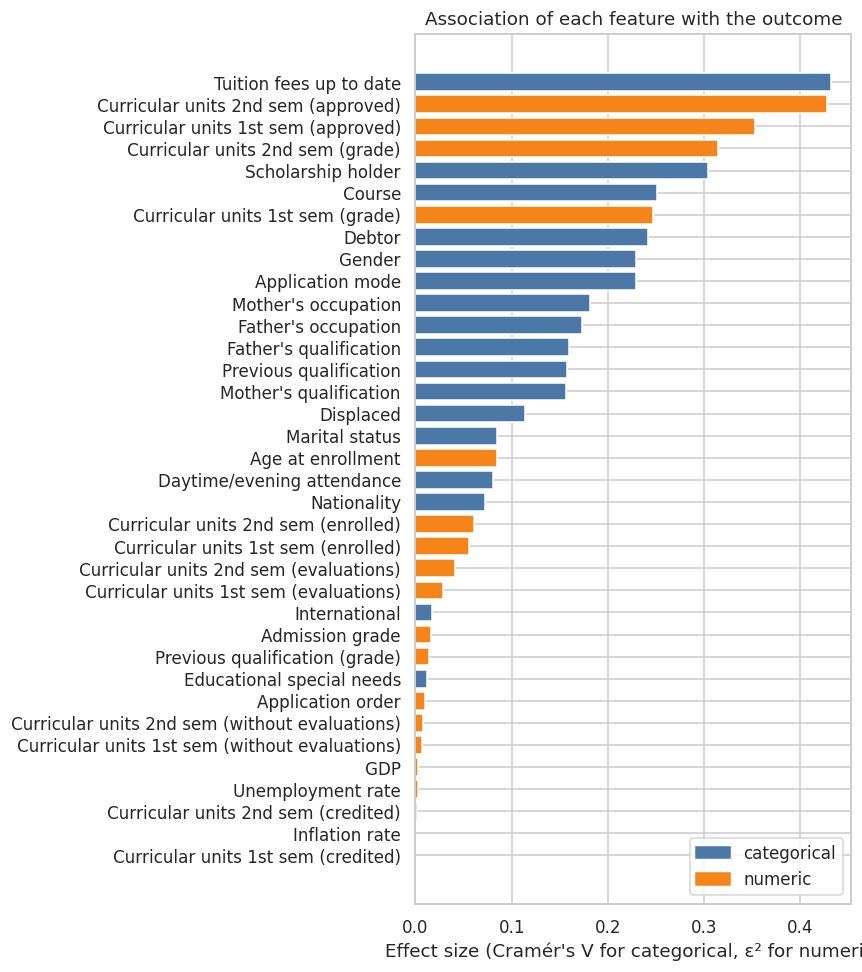

In [4]:
fig, ax = plt.subplots(figsize=(8, 9))
top = stat_df.sort_values('effect_size')
colors = top['type'].map({'categorical': '#4C78A8', 'numeric': '#F58518'})
ax.barh(top['feature'], top['effect_size'], color=colors)
ax.set_xlabel("Effect size (Cramér's V for categorical, ε² for numeric)")
ax.set_title('Association of each feature with the outcome')
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color='#4C78A8', label='categorical'), Patch(color='#F58518', label='numeric')], loc='lower right')
plt.tight_layout(); plt.savefig('figures/01_effect_sizes.png', bbox_inches='tight'); plt.show()

### Pairwise follow-up and a key predictor
Kruskal-Wallis only says *some* group differs. For the strongest numeric feature we run **Dunn's post-hoc test** (Bonferroni-adjusted) to see which pairs differ.

Strongest numeric feature: Curricular units 2nd sem (approved)
          Dropout  Enrolled  Graduate
Dropout       1.0       0.0       0.0
Enrolled      0.0       1.0       0.0
Graduate      0.0       0.0       1.0


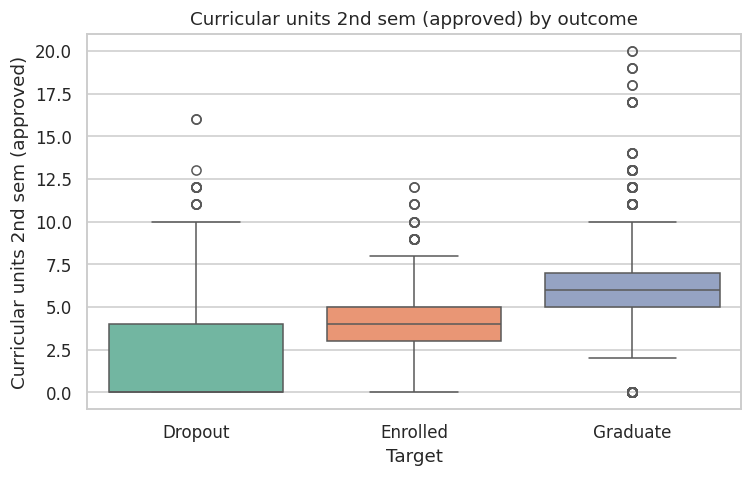

In [5]:
best_num = stat_df[stat_df['type'] == 'numeric'].iloc[0]['feature']
print('Strongest numeric feature:', best_num)
dunn = sp.posthoc_dunn(df.assign(v=X[best_num]), val_col='v', group_col='Target', p_adjust='bonferroni')
print(dunn.round(5))
plt.figure(figsize=(7, 4.5))
sns.boxplot(data=df, x='Target', y=best_num, order=class_names, palette='Set2')
plt.title(f'{best_num} by outcome'); plt.tight_layout()
plt.savefig('figures/02_top_feature_boxplot.png', bbox_inches='tight'); plt.show()

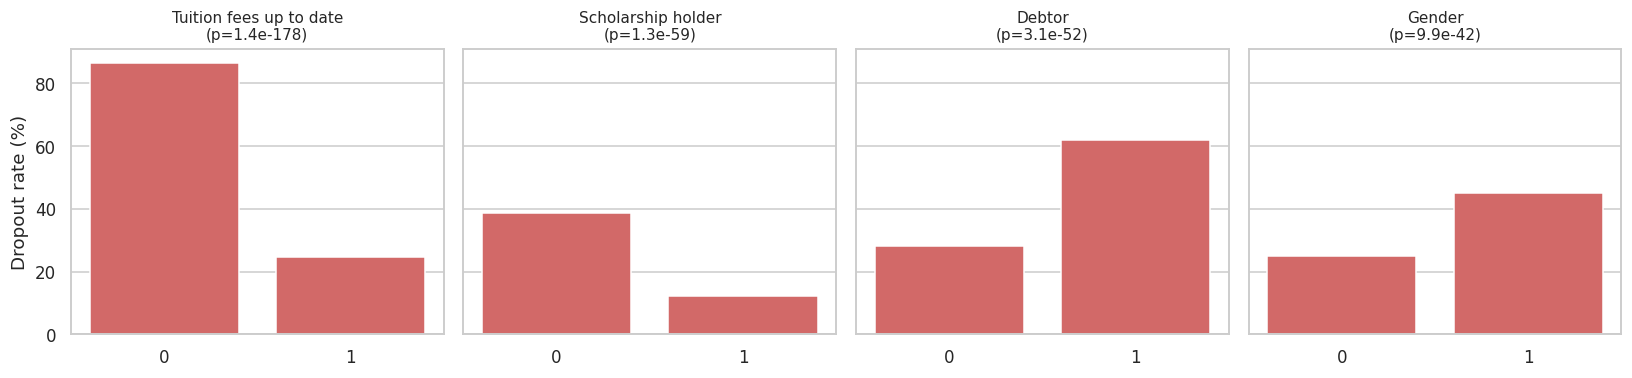

In [6]:
# Dropout rate by key financial / demographic variables (+ chi-square on the 2x2 table)
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6), sharey=True)
for ax, c in zip(axes, ['Tuition fees up to date', 'Scholarship holder', 'Debtor', 'Gender']):
    r = (df['Target'] == 'Dropout').groupby(X[c]).mean() * 100
    sns.barplot(x=r.index, y=r.values, ax=ax, color='#E45756')
    chi2, p, _, _ = stats.chi2_contingency(pd.crosstab(X[c], df['Target'] == 'Dropout'))
    ax.set_title(f'{c}\n(p={p:.1e})', fontsize=10); ax.set_xlabel(''); ax.set_ylabel('Dropout rate (%)')
plt.tight_layout(); plt.savefig('figures/03_dropout_rates.png', bbox_inches='tight'); plt.show()

## 3. Feature selection
We compare three families of methods, each keeping **k = 15** features:

* **Filter** - Mutual Information (model-free, fast)
* **Embedded** - Random Forest importance (selection happens while the model learns)
* **Wrapper** - Recursive Feature Elimination (RFE) with Logistic Regression (repeatedly drops the weakest feature)

To avoid **data leakage**, selection is fitted on the *training split only*, and during cross-validation it sits *inside* the pipeline.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
K = 15

sel_filter = SelectKBest(mutual_info_classif, k=K).fit(X_train, y_train)
sel_embedded = SelectFromModel(RandomForestClassifier(200, random_state=RANDOM_STATE), max_features=K, threshold=-np.inf).fit(X_train, y_train)
sel_wrapper = RFE(LogisticRegression(max_iter=2000), n_features_to_select=K, step=3)
sel_wrapper.fit(StandardScaler().fit_transform(X_train), y_train)

chosen = {
    'Filter (MI)': set(X.columns[sel_filter.get_support()]),
    'Embedded (RF)': set(X.columns[sel_embedded.get_support()]),
    'Wrapper (RFE-LR)': set(X.columns[sel_wrapper.support_]),
}
votes = pd.DataFrame({m: [f in s for f in X.columns] for m, s in chosen.items()}, index=X.columns).astype(int)
votes['votes'] = votes.sum(axis=1)
votes = votes.sort_values('votes', ascending=False)
consensus = list(votes[votes['votes'] >= 2].index)
print(f'{len(consensus)} features chosen by at least 2 of 3 methods:')
votes[votes['votes'] > 0]

15 features chosen by at least 2 of 3 methods:


,Filter (MI),Embedded (RF),Wrapper (RFE-LR),votes
Course,1,1,1,3
Curricular units 2nd sem (grade),1,1,1,3
Age at enrollment,1,1,1,3
Tuition fees up to date,1,1,1,3
Curricular units 2nd sem (evaluations),1,1,1,3
Curricular units 2nd sem (approved),1,1,1,3
Curricular units 1st sem (approved),1,1,1,3
Curricular units 1st sem (evaluations),1,1,0,2
Curricular units 1st sem (enrolled),1,0,1,2
Curricular units 1st sem (grade),1,1,0,2


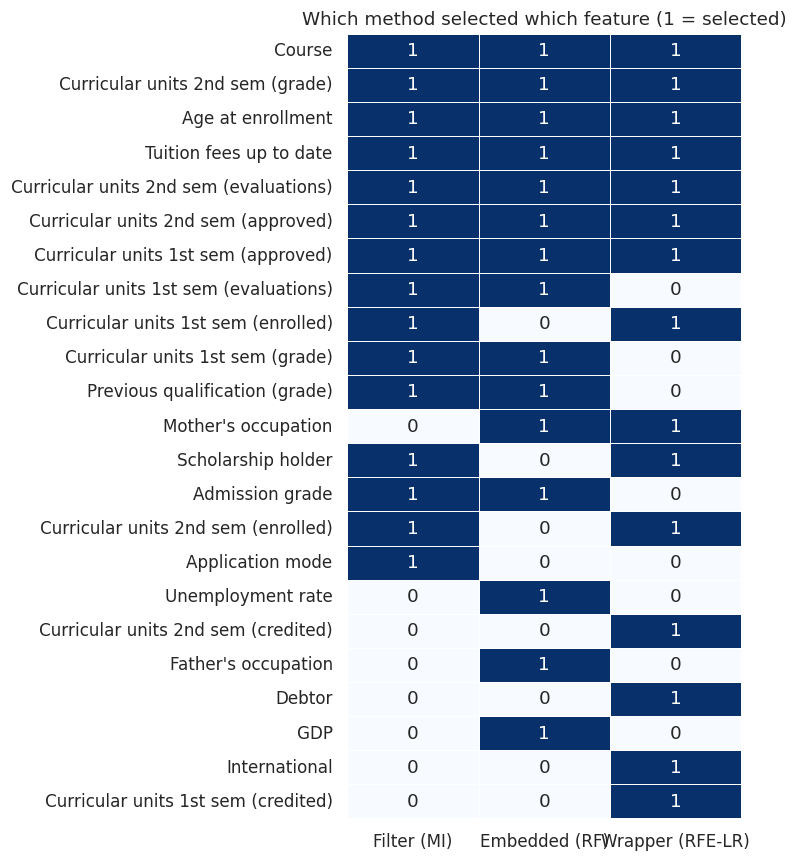

In [8]:
fig, ax = plt.subplots(figsize=(7, 8))
sns.heatmap(votes[votes['votes'] > 0].drop(columns='votes'), annot=True, cbar=False, cmap='Blues', linewidths=.5, ax=ax)
ax.set_title('Which method selected which feature (1 = selected)')
plt.tight_layout(); plt.savefig('figures/04_feature_selection_votes.png', bbox_inches='tight'); plt.show()

## 4. Model comparison with the Friedman test
**Why Friedman?** We want to know whether differences between several classifiers are *statistically real* or just noise from the particular data split.
The Friedman test is the non-parametric alternative to repeated-measures ANOVA: each CV fold is a "block", classifiers are ranked inside each block, and we test whether mean ranks differ.

* H0: all classifiers perform equally.
* If H0 is rejected -> **Nemenyi post-hoc** tells which pairs differ, shown in a *critical-difference diagram*.

We use **5x2 repeated stratified CV** (10 blocks) and **macro-F1** (fair for imbalanced classes).

In [9]:
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=RANDOM_STATE)
models = {
    'Logistic Reg.': make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)),
    'Decision Tree': DecisionTreeClassifier(max_depth=6, random_state=RANDOM_STATE),
    'SVM (RBF)': make_pipeline(StandardScaler(), SVC(random_state=RANDOM_STATE)),
    'Random Forest': RandomForestClassifier(150, random_state=RANDOM_STATE),
    'XGBoost': XGBClassifier(n_estimators=150, max_depth=4, learning_rate=0.1, subsample=0.8,
                             colsample_bytree=0.8, eval_metric='mlogloss', random_state=RANDOM_STATE),
}
scores = {name: cross_val_score(m, X, y, cv=cv, scoring='f1_macro') for name, m in models.items()}
score_df = pd.DataFrame(scores)
print(score_df.agg(['mean', 'std']).round(4).T)

                 mean     std
Logistic Reg.  0.6740  0.0149
Decision Tree  0.6622  0.0166
SVM (RBF)      0.6729  0.0126
Random Forest  0.6921  0.0094
XGBoost        0.7126  0.0122


In [10]:
stat, p = stats.friedmanchisquare(*[score_df[c] for c in score_df.columns])
print(f'Friedman chi-square = {stat:.3f}, p = {p:.5f}')
print('-> Reject H0: classifiers differ significantly' if p < 0.05 else '-> Cannot reject H0')

ranks = score_df.rank(axis=1, ascending=False)   # rank 1 = best in each fold
mean_ranks = ranks.mean().sort_values()
print('\nMean ranks (lower = better):'); print(mean_ranks.round(2))

# Kendall's W: effect size for Friedman (0 = no agreement, 1 = perfect agreement)
n_blocks, k = score_df.shape
print(f"Kendall's W = {stat / (n_blocks * (k - 1)):.3f}")

nemenyi = sp.posthoc_nemenyi_friedman(score_df.values)
nemenyi.index = nemenyi.columns = score_df.columns
print('\nNemenyi p-values:'); print(nemenyi.round(4))

Friedman chi-square = 31.120, p = 0.00000
-> Reject H0: classifiers differ significantly

Mean ranks (lower = better):
XGBoost          1.1
Random Forest    2.1
SVM (RBF)        3.4
Logistic Reg.    3.8
Decision Tree    4.6
dtype: float64
Kendall's W = 0.778

Nemenyi p-values:
               Logistic Reg.  Decision Tree  SVM (RBF)  Random Forest  XGBoost
Logistic Reg.         1.0000         0.7899     0.9800         0.1141   0.0013
Decision Tree         0.7899         1.0000     0.4357         0.0037   0.0000
SVM (RBF)             0.9800         0.4357     1.0000         0.3513   0.0101
Random Forest         0.1141         0.0037     0.3513         1.0000   0.6184
XGBoost               0.0013         0.0000     0.0101         0.6184   1.0000


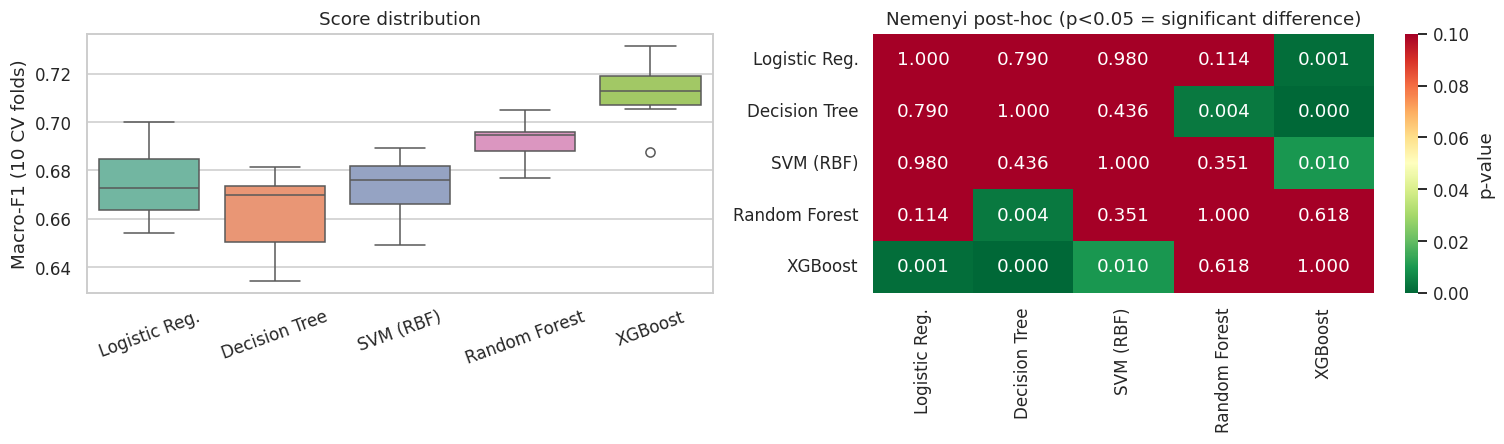

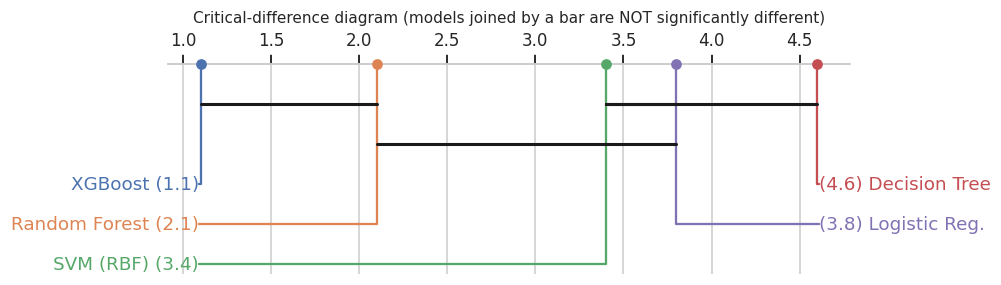

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
sns.boxplot(data=score_df, ax=axes[0], palette='Set2'); axes[0].set_ylabel('Macro-F1 (10 CV folds)')
axes[0].set_title('Score distribution'); axes[0].tick_params(axis='x', rotation=20)
sns.heatmap(nemenyi, annot=True, fmt='.3f', cmap='RdYlGn_r', vmin=0, vmax=0.1, ax=axes[1], cbar_kws={'label': 'p-value'})
axes[1].set_title('Nemenyi post-hoc (p<0.05 = significant difference)')
plt.tight_layout(); plt.savefig('figures/05_friedman_nemenyi.png', bbox_inches='tight'); plt.show()

plt.figure(figsize=(8, 2.6))
sp.critical_difference_diagram(mean_ranks, nemenyi)
plt.title('Critical-difference diagram (models joined by a bar are NOT significantly different)', fontsize=10)
plt.savefig('figures/06_critical_difference.png', bbox_inches='tight'); plt.show()

### 4b. Does feature selection hurt performance? (second Friedman test)
Same idea, now the "treatments" are *feature sets*, using XGBoost. Selection is done inside each CV fold through a Pipeline so there is no leakage.

                      mean     std
All 36 features     0.7126  0.0122
Filter MI (k=15)    0.7008  0.0123
Embedded RF (k=15)  0.7021  0.0124
Wrapper RFE (k=15)  0.7038  0.0106

Friedman chi-square = 8.760, p = 0.0327
                    All 36 features  Filter MI (k=15)  Embedded RF (k=15)  \
All 36 features               1.000             0.029               0.110   
Filter MI (k=15)              0.029             1.000               0.954   
Embedded RF (k=15)            0.110             0.954               1.000   
Wrapper RFE (k=15)            0.226             0.822               0.986   

                    Wrapper RFE (k=15)  
All 36 features                  0.226  
Filter MI (k=15)                 0.822  
Embedded RF (k=15)               0.986  
Wrapper RFE (k=15)               1.000  


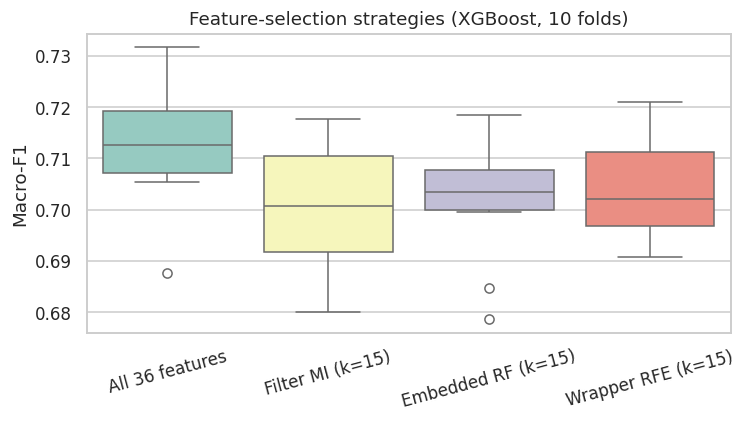

In [12]:
xgb = lambda: XGBClassifier(n_estimators=150, max_depth=4, learning_rate=0.1, subsample=0.8,
                            colsample_bytree=0.8, eval_metric='mlogloss', random_state=RANDOM_STATE)
fs_pipes = {
    'All 36 features': xgb(),
    f'Filter MI (k={K})': Pipeline([('s', SelectKBest(mutual_info_classif, k=K)), ('m', xgb())]),
    f'Embedded RF (k={K})': Pipeline([('s', SelectFromModel(RandomForestClassifier(100, random_state=RANDOM_STATE), max_features=K, threshold=-np.inf)), ('m', xgb())]),
    f'Wrapper RFE (k={K})': Pipeline([('s', RFE(LogisticRegression(max_iter=1000), n_features_to_select=K, step=4)), ('m', xgb())]),
}
# RFE with logistic regression needs scaled input
fs_pipes[f'Wrapper RFE (k={K})'] = Pipeline([('sc', StandardScaler()), ('s', RFE(LogisticRegression(max_iter=1000), n_features_to_select=K, step=4)), ('m', xgb())])
fs_scores = pd.DataFrame({n: cross_val_score(p_, X, y, cv=cv, scoring='f1_macro') for n, p_ in fs_pipes.items()})
print(fs_scores.agg(['mean', 'std']).round(4).T)
stat2, p2 = stats.friedmanchisquare(*[fs_scores[c] for c in fs_scores.columns])
print(f'\nFriedman chi-square = {stat2:.3f}, p = {p2:.4f}')
nem2 = sp.posthoc_nemenyi_friedman(fs_scores.values); nem2.index = nem2.columns = fs_scores.columns
print(nem2.round(3))
plt.figure(figsize=(7, 4)); sns.boxplot(data=fs_scores, palette='Set3'); plt.xticks(rotation=15)
plt.ylabel('Macro-F1'); plt.title('Feature-selection strategies (XGBoost, 10 folds)')
plt.tight_layout(); plt.savefig('figures/07_feature_selection_friedman.png', bbox_inches='tight'); plt.show()

## 5. Final model
We train **XGBoost** on the consensus features (selected by >= 2 of the 3 methods) and evaluate on the untouched test set.

              precision    recall  f1-score   support

     Dropout      0.807     0.736     0.770       284
    Enrolled      0.526     0.440     0.479       159
    Graduate      0.815     0.910     0.860       442

    accuracy                          0.769       885
   macro avg      0.716     0.695     0.703       885
weighted avg      0.761     0.769     0.763       885



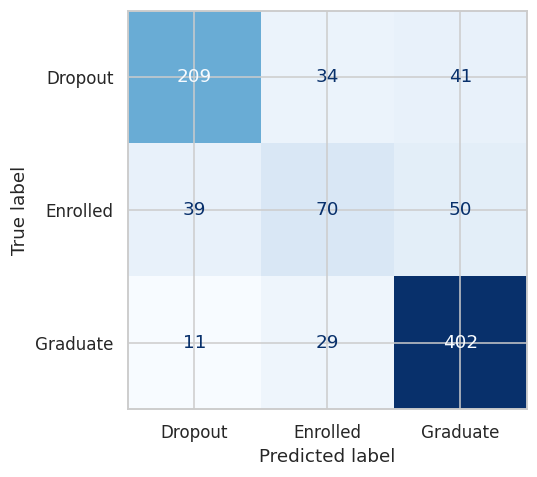

Features used: ['Course', 'Curricular units 2nd sem (grade)', 'Age at enrollment', 'Tuition fees up to date', 'Curricular units 2nd sem (evaluations)', 'Curricular units 2nd sem (approved)', 'Curricular units 1st sem (approved)', 'Curricular units 1st sem (evaluations)', 'Curricular units 1st sem (enrolled)', 'Curricular units 1st sem (grade)', 'Previous qualification (grade)', "Mother's occupation", 'Scholarship holder', 'Admission grade', 'Curricular units 2nd sem (enrolled)']


In [13]:
final_feats = consensus
model = xgb().fit(X_train[final_feats], y_train)
pred = model.predict(X_test[final_feats])
print(classification_report(y_test, pred, target_names=class_names, digits=3))
fig, ax = plt.subplots(figsize=(5, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=class_names).plot(ax=ax, cmap='Blues', colorbar=False)
plt.tight_layout(); plt.savefig('figures/08_confusion_matrix.png', bbox_inches='tight'); plt.show()
print('Features used:', final_feats)

## 6. SHAP - Shapley-value explanations
**Idea:** SHAP assigns each feature a contribution to a prediction using Shapley values from game theory. Contributions add up exactly: `base value + sum(SHAP) = model output`.

* **Global** view -> which features matter overall, and in which direction
* **Local** view -> why *this one student* got this prediction

`TreeExplainer` is exact and fast for tree ensembles like XGBoost.

In [14]:
Xs = X_test[final_feats]
explainer = shap.TreeExplainer(model)
sv = explainer.shap_values(Xs)
sv = np.stack(sv, axis=-1) if isinstance(sv, list) else sv          # -> (n_samples, n_features, n_classes)
base = np.atleast_1d(explainer.expected_value)
print('SHAP array shape:', sv.shape)

SHAP array shape: (885, 15, 3)


### 6a. Global importance - bar plot (mean |SHAP|, split by class)

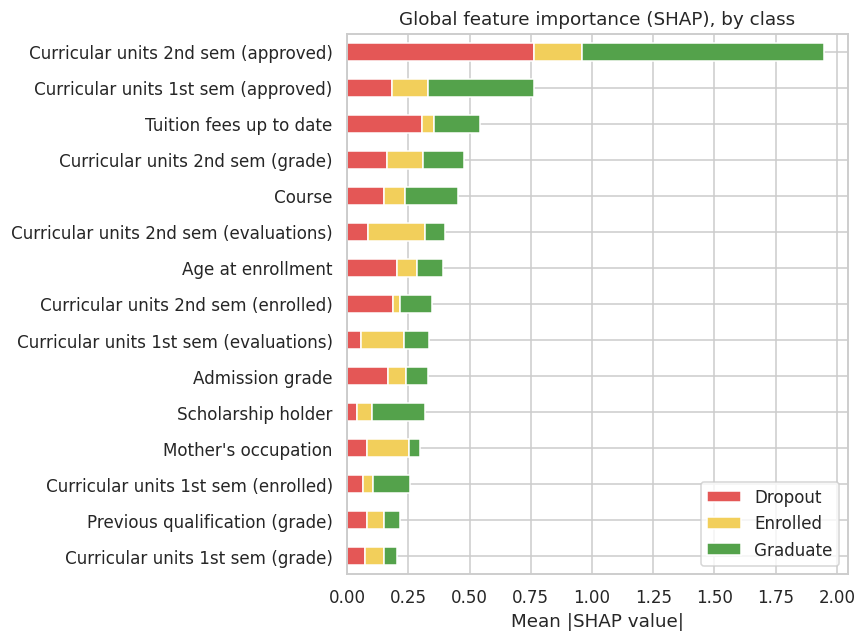

In [15]:
mean_abs = np.abs(sv).mean(axis=0)          # (features, classes)
imp = pd.DataFrame(mean_abs, index=final_feats, columns=class_names)
imp = imp.loc[imp.sum(axis=1).sort_values().index]
imp.plot(kind='barh', stacked=True, figsize=(8, 6), color=['#E45756', '#F2CF5B', '#54A24B'])
plt.xlabel('Mean |SHAP value|'); plt.title('Global feature importance (SHAP), by class')
plt.tight_layout(); plt.savefig('figures/09_shap_bar.png', bbox_inches='tight'); plt.show()

### 6b. Beeswarm (summary) plot for the Dropout class
Each dot is one student. **Horizontal position** = effect on dropout risk (right = pushes toward dropout). **Colour** = feature value (red = high, blue = low).

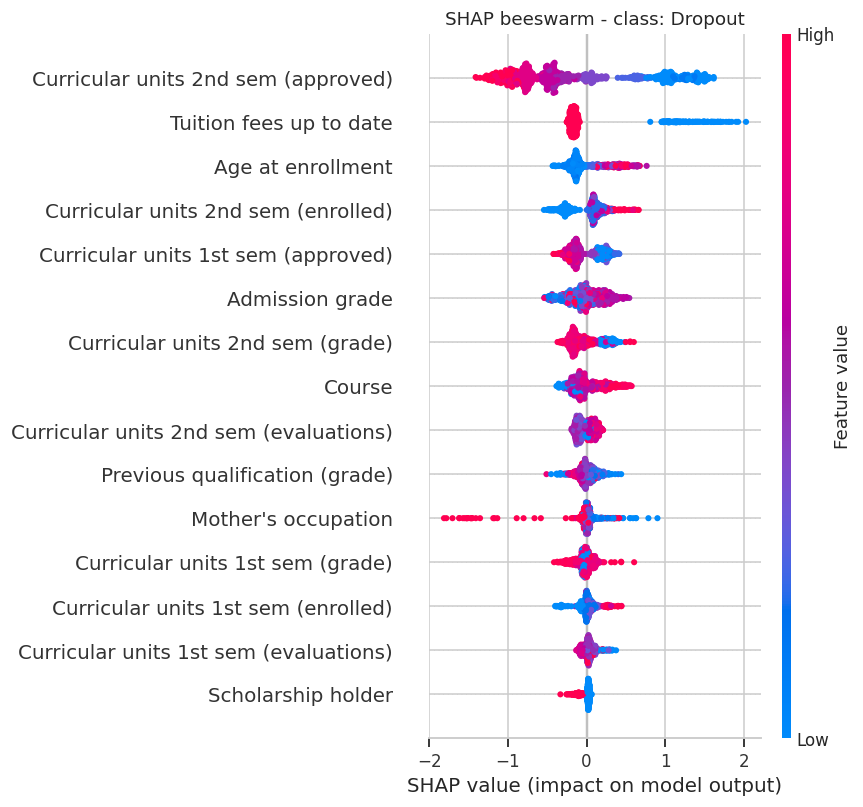

In [16]:
c_drop = class_names.index('Dropout')
shap.summary_plot(sv[:, :, c_drop], Xs, show=False, max_display=15)
plt.title('SHAP beeswarm - class: Dropout'); plt.tight_layout()
plt.savefig('figures/10_shap_beeswarm_dropout.png', bbox_inches='tight'); plt.show()

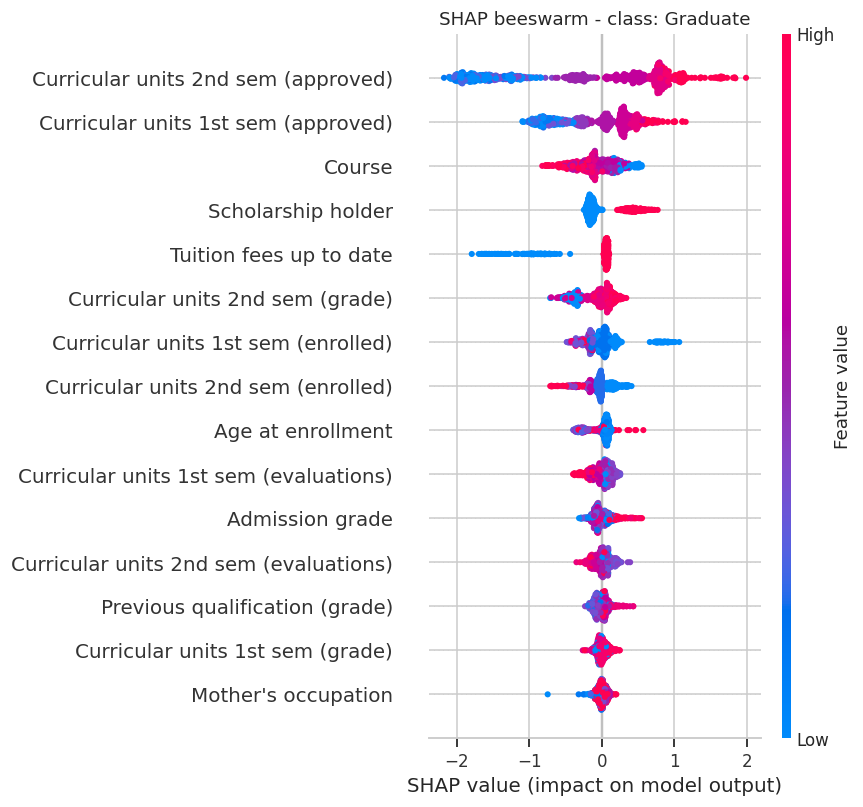

In [17]:
c_grad = class_names.index('Graduate')
shap.summary_plot(sv[:, :, c_grad], Xs, show=False, max_display=15)
plt.title('SHAP beeswarm - class: Graduate'); plt.tight_layout()
plt.savefig('figures/11_shap_beeswarm_graduate.png', bbox_inches='tight'); plt.show()

### 6c. Dependence plots - how a feature's value changes its effect (and interactions)

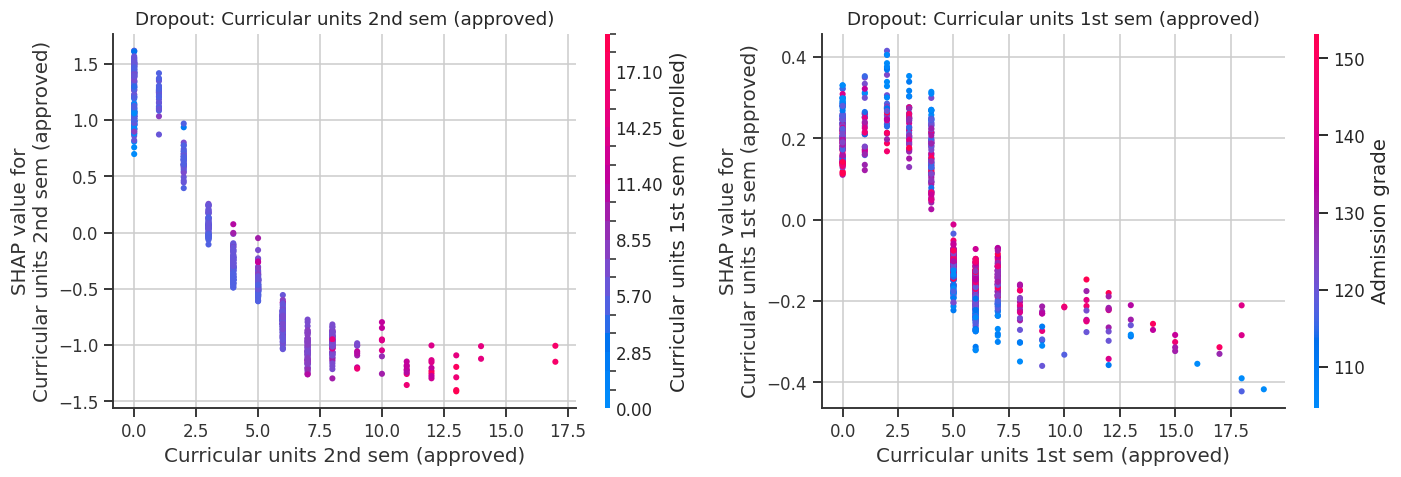

In [18]:
top_feats = list(imp.index[::-1][:2])
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, f in zip(axes, top_feats):
    shap.dependence_plot(f, sv[:, :, c_drop], Xs, ax=ax, show=False)
    ax.set_title(f'Dropout: {f}')
plt.tight_layout(); plt.savefig('figures/12_shap_dependence.png', bbox_inches='tight'); plt.show()

### 6d. Local explanations - waterfall plots
We explain three students: one confidently predicted **Dropout**, one **Graduate**, and one **Enrolled**.
Bars show how each feature pushes the prediction away from the average (base value).

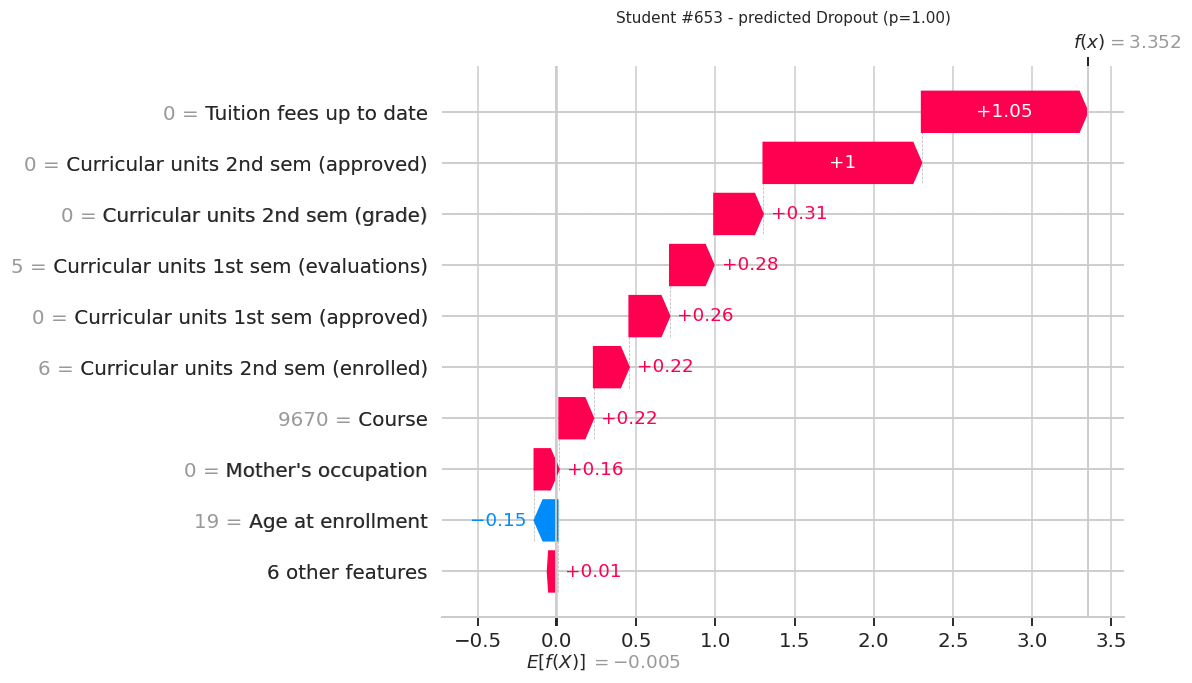

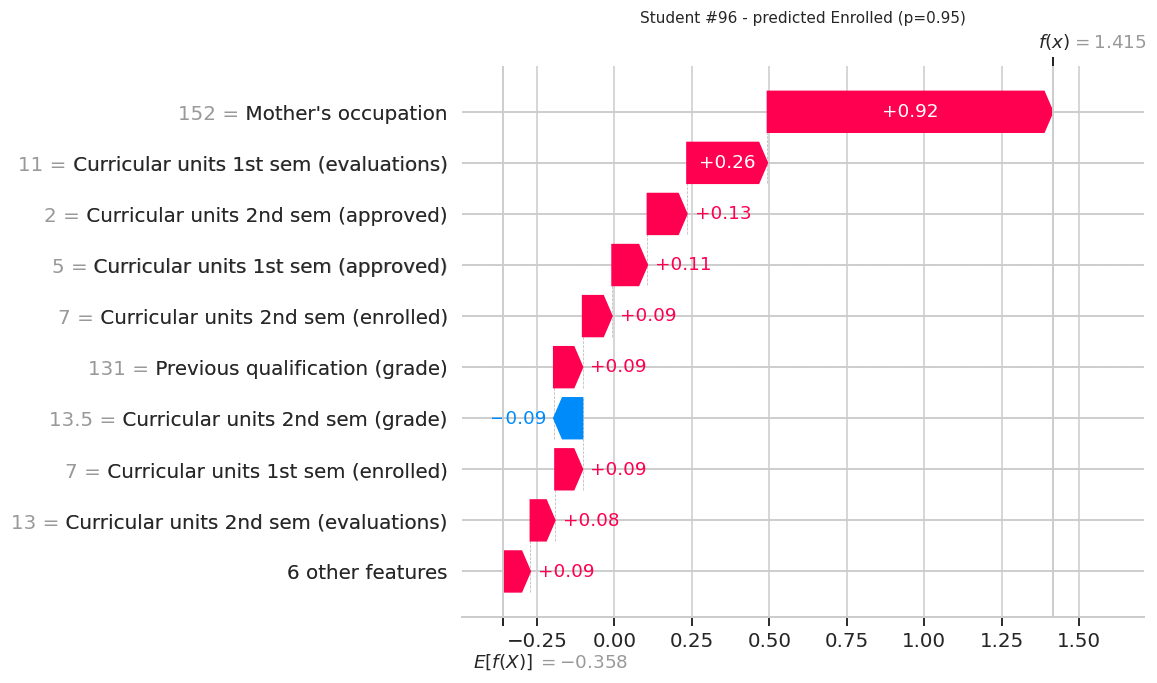

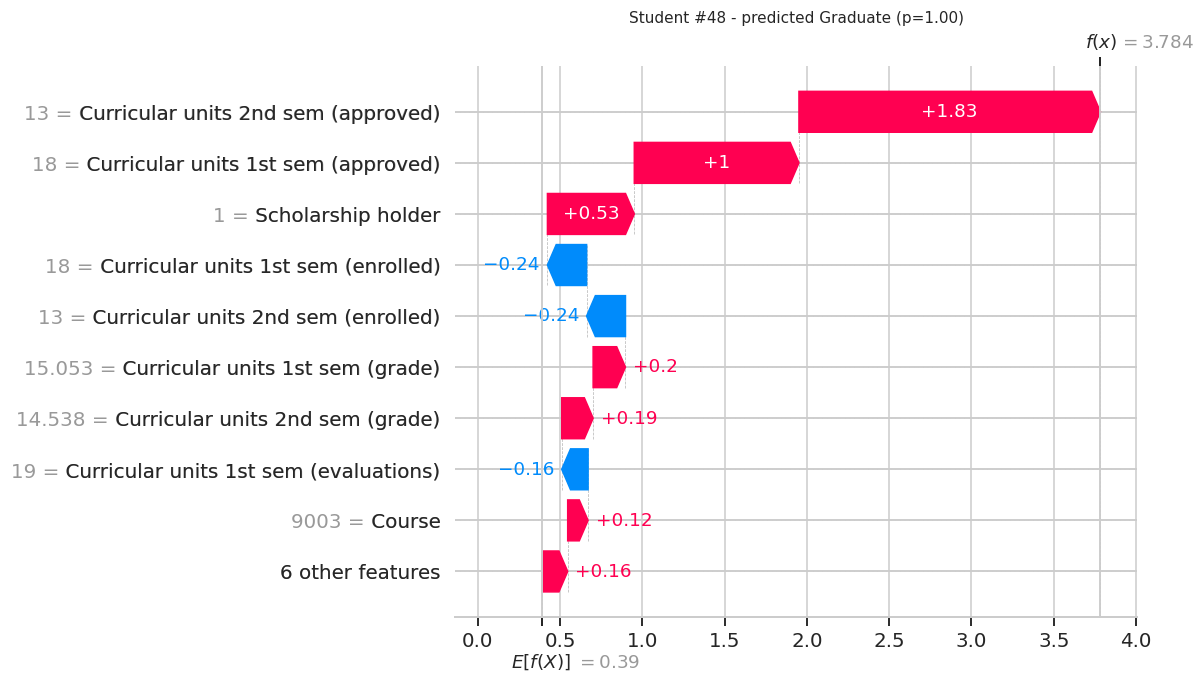

In [19]:
proba = model.predict_proba(Xs)
picks = {}
for cname in class_names:
    c = class_names.index(cname)
    idx = np.where((pred == c) & (y_test.values == c))[0]
    picks[cname] = idx[np.argmax(proba[idx, c])]
for cname, i in picks.items():
    c = class_names.index(cname)
    ex = shap.Explanation(values=sv[i, :, c], base_values=base[c], data=Xs.iloc[i].values, feature_names=final_feats)
    shap.plots.waterfall(ex, max_display=10, show=False)
    plt.title(f'Student #{i} - predicted {cname} (p={proba[i, c]:.2f})', fontsize=10)
    plt.savefig(f'figures/13_shap_waterfall_{cname}.png', bbox_inches='tight'); plt.show()

## 7. LIME - Local Interpretable Model-agnostic Explanations
**Idea:** for one student, LIME generates many slightly perturbed copies, asks the black-box model for predictions, and fits a simple weighted **linear model** around that point. The coefficients are the explanation.

Unlike SHAP's TreeExplainer, LIME is *model-agnostic* (only needs `predict_proba`) and purely local, but it is **stochastic** (results vary between runs) and sensitive to the chosen neighbourhood.

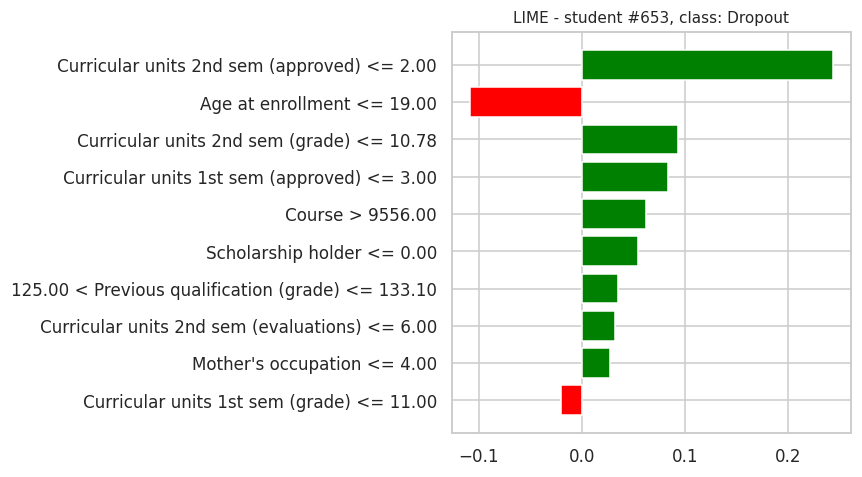

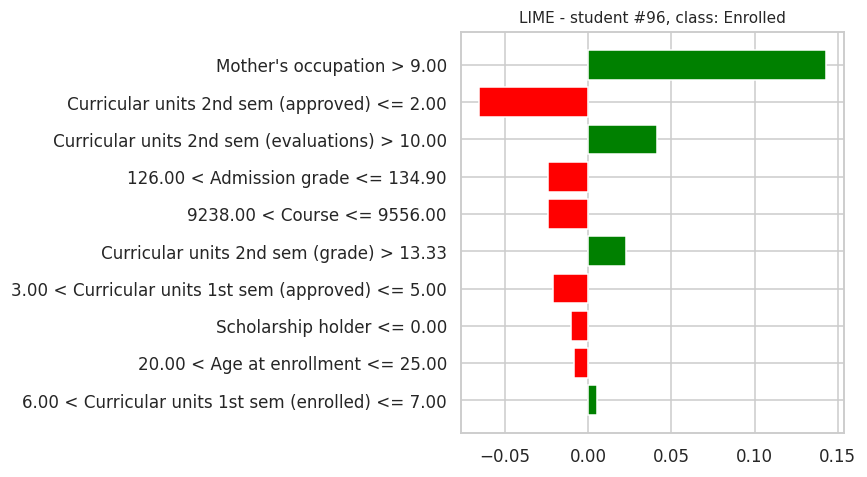

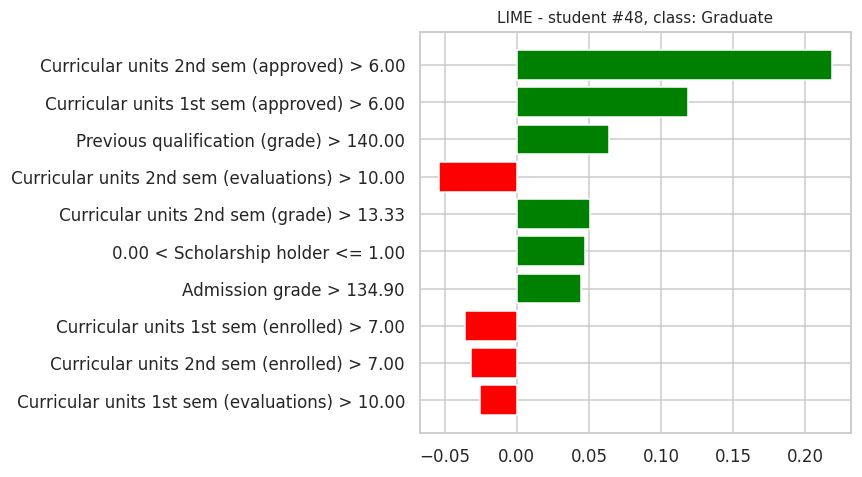

In [20]:
lime_exp = lime.lime_tabular.LimeTabularExplainer(
    training_data=X_train[final_feats].values, feature_names=final_feats, class_names=class_names,
    mode='classification', discretize_continuous=True, random_state=RANDOM_STATE)

for cname, i in picks.items():
    c = class_names.index(cname)
    exp = lime_exp.explain_instance(Xs.iloc[i].values, model.predict_proba, num_features=10, labels=(c,), num_samples=5000)
    fig = exp.as_pyplot_figure(label=c)
    fig.set_size_inches(8, 4.5)
    plt.title(f'LIME - student #{i}, class: {cname}', fontsize=10); plt.tight_layout()
    plt.savefig(f'figures/14_lime_{cname}.png', bbox_inches='tight'); plt.show()
    exp.save_to_file(f'figures/lime_{cname}.html')   # interactive HTML version

## 8. SHAP vs LIME - do they agree?
For 40 test students we take the top-10 features according to each method (for the predicted class) and measure
* **Jaccard overlap** of the two top-10 sets
* **Spearman correlation** of the absolute attributions

This is a useful *evaluation of the explanations themselves* and a nice statistical addition to the project.

       jaccard_top10  spearman
count         40.000    40.000
mean           0.587     0.422
std            0.120     0.167
min            0.429     0.004
25%            0.538     0.312
50%            0.538     0.436
75%            0.667     0.533
max            0.818     0.764


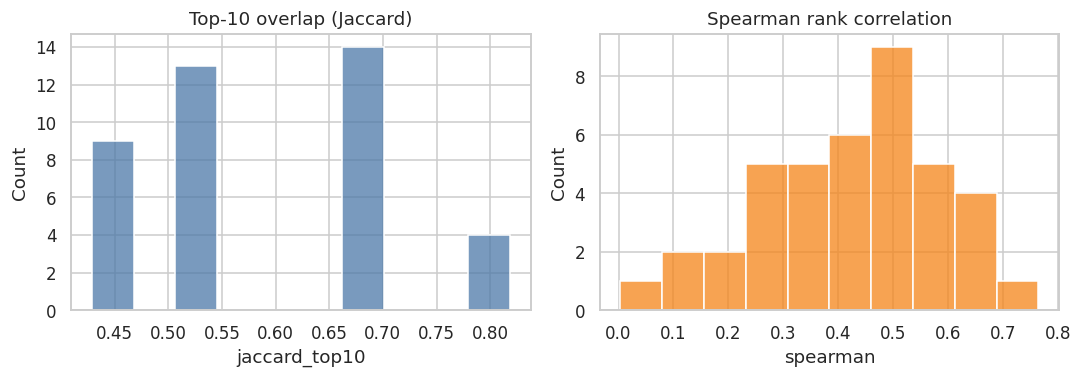

In [21]:
rng = np.random.RandomState(RANDOM_STATE)
sample_idx = rng.choice(len(Xs), 40, replace=False)
jacc, spear = [], []
for i in sample_idx:
    c = pred[i]
    shap_abs = pd.Series(np.abs(sv[i, :, c]), index=final_feats)
    e = lime_exp.explain_instance(Xs.iloc[i].values, model.predict_proba, num_features=len(final_feats), labels=(c,), num_samples=3000)
    lime_abs = pd.Series(0.0, index=final_feats)
    for fname, w in e.as_list(label=c):
        # LIME returns discretised names such as 'Age at enrollment <= 19.0'; match back to the feature
        match = [f for f in final_feats if fname.startswith(f) or f in fname]
        match = sorted(match, key=len, reverse=True)
        if match: lime_abs[match[0]] = abs(w)
    a, b = set(shap_abs.nlargest(10).index), set(lime_abs.nlargest(10).index)
    jacc.append(len(a & b) / len(a | b))
    spear.append(stats.spearmanr(shap_abs, lime_abs)[0])
agree = pd.DataFrame({'jaccard_top10': jacc, 'spearman': spear})
print(agree.describe().round(3))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
sns.histplot(agree['jaccard_top10'], bins=10, ax=axes[0], color='#4C78A8'); axes[0].set_title('Top-10 overlap (Jaccard)')
sns.histplot(agree['spearman'], bins=10, ax=axes[1], color='#F58518'); axes[1].set_title('Spearman rank correlation')
plt.tight_layout(); plt.savefig('figures/15_shap_vs_lime.png', bbox_inches='tight'); plt.show()

## 9. Fairness audit through explanations
**Question:** does the model make different *kinds of mistakes* for different groups, and does it *rely on features differently* (for example age) depending on the group?

**Setup**
* Screening rule: a student is **flagged at risk** if the model gives `P(dropout) >= 0.5`. Positive class = Dropout.
* Costs of errors are not equal: a **false negative** is a student who needed help and was missed; a **false positive** is a student flagged unnecessarily.
* Sensitive attributes: **Gender**, **Age group** (<=20, 21-24, 25-29, 30+) and **Nationality** (Portuguese vs non-Portuguese).
* To get enough students per group we use **5-fold out-of-fold predictions and SHAP values for all 4,424 students**, so each student is explained by a model that never saw them.

| Fairness notion | What we compare across groups |
|---|---|
| Demographic parity | share of students flagged |
| **Equal opportunity** | recall of real dropouts (TPR): who gets missed? |
| Equalized odds | TPR *and* false-positive rate (FPR) |
| Accuracy parity | overall accuracy |

Groups can have different true dropout rates, so demographic-parity gaps alone do not prove unfairness. Equal opportunity is usually the most relevant lens for a support programme.

In [22]:
# ---------- 9.1 groups ----------
age_order = ['<=20', '21-24', '25-29', '30+']
sens = pd.DataFrame({
    'Gender': X['Gender'].map({0: 'Female', 1: 'Male'}),
    'Age group': pd.cut(X['Age at enrollment'], [0, 20, 24, 29, 100], labels=age_order).astype(str),
    'Nationality': np.where(X['Nationality'] == 1, 'Portuguese', 'Non-Portuguese'),
})
order = {'Gender': ['Female', 'Male'], 'Age group': age_order, 'Nationality': ['Portuguese', 'Non-Portuguese']}
codes = {a: sens[a].map({g: i for i, g in enumerate(order[a])}).values for a in order}
is_drop = (y.values == class_names.index('Dropout')).astype(int)
c_drop = class_names.index('Dropout')
THR = 0.5

summary = pd.concat([pd.DataFrame({'n': sens[a].value_counts(), 'true dropout rate': pd.Series(is_drop, index=sens.index).groupby(sens[a]).mean().round(3)}).loc[order[a]].assign(attribute=a) for a in order])
summary.set_index('attribute', append=True).swaplevel()

n  true dropout rate
attribute                                          
Gender      Female          2868              0.251
            Male            1556              0.451
Age group   <=20            2551              0.212
            21-24            735              0.337
            25-29            427              0.576
            30+              711              0.541
Nationality Portuguese      4314              0.322
            Non-Portuguese   110              0.291

In [23]:
# ---------- 9.2 out-of-fold predictions (+ SHAP) for three models ----------
from sklearn.model_selection import StratifiedKFold
F_feats = final_feats                                   # the model we have been explaining
S_feats = final_feats + ['Gender', 'International']     # 'audit' model: sensitive attributes available, so we can see if they are used
B_feats = [f for f in final_feats if f != 'Age at enrollment']   # 'blind' model: age removed

def oof_predict(feats, with_shap=False, seed=RANDOM_STATE):
    skf = StratifiedKFold(5, shuffle=True, random_state=seed)
    P = np.zeros((len(X), 3)); SV = np.zeros((len(X), len(feats), 3)) if with_shap else None
    for tr, te in skf.split(X, y):
        m = xgb().fit(X.iloc[tr][feats], y.iloc[tr])
        P[te] = m.predict_proba(X.iloc[te][feats])
        if with_shap:
            s = shap.TreeExplainer(m).shap_values(X.iloc[te][feats])
            SV[te] = np.stack(s, axis=-1) if isinstance(s, list) else s
    return P, SV

proba_F, _ = oof_predict(F_feats)
proba_S, sv_S = oof_predict(S_feats, with_shap=True)
proba_B, _ = oof_predict(B_feats)
flag = lambda P, t=THR: (P[:, c_drop] >= t).astype(int)
fl_F = flag(proba_F)
print('Out-of-fold accuracy (argmax):', {n: round((P.argmax(1) == y.values).mean(), 3) for n, P in [('F', proba_F), ('S', proba_S), ('B', proba_B)]})

Out-of-fold accuracy (argmax): {'F': np.float64(0.773), 'S': np.float64(0.773), 'B': np.float64(0.776)}


### 9.3 Error rates by group (with bootstrap 95% confidence intervals)

In [24]:
def mval(metric, yt, fl):
    if len(yt) == 0: return np.nan
    if metric == 'flag_rate': return fl.mean()
    if metric == 'TPR': return fl[yt == 1].mean()
    if metric == 'FPR': return fl[yt == 0].mean()
    if metric == 'accuracy': return (fl == yt).mean()
    if metric == 'precision': return yt[fl == 1].mean() if fl.sum() else np.nan

METRICS = ['flag_rate', 'TPR', 'FPR', 'accuracy']

def audit_table(fl, B=500):
    rows = []
    for attr in order:
        for i, g in enumerate(order[attr]):
            idx = np.where(codes[attr] == i)[0]
            r = {'attribute': attr, 'group': g, 'n': len(idx)}
            r.update({m: mval(m, is_drop[idx], fl[idx]) for m in METRICS})
            rng = np.random.RandomState(0)
            boots = np.array([[mval(m, is_drop[b], fl[b]) for m in METRICS] for b in (rng.choice(idx, len(idx)) for _ in range(B))])
            lo, hi = np.nanpercentile(boots, 2.5, axis=0), np.nanpercentile(boots, 97.5, axis=0)
            for k, m in enumerate(METRICS): r[m + '_lo'], r[m + '_hi'] = lo[k], hi[k]
            rows.append(r)
    return pd.DataFrame(rows)

gt = audit_table(fl_F)
gt[['attribute', 'group', 'n'] + METRICS].round(3)

,attribute,group,n,flag_rate,TPR,FPR,accuracy
0,Gender,Female,2868,0.212,0.714,0.044,0.895
1,Gender,Male,1556,0.399,0.756,0.106,0.832
2,Age group,<=20,2551,0.160,0.600,0.041,0.883
3,Age group,21-24,735,0.294,0.677,0.099,0.826
4,Age group,25-29,427,0.541,0.858,0.110,0.871
5,Age group,30+,711,0.527,0.883,0.107,0.887
6,Nationality,Portuguese,4314,0.277,0.733,0.060,0.873
7,Nationality,Non-Portuguese,110,0.318,0.812,0.115,0.864


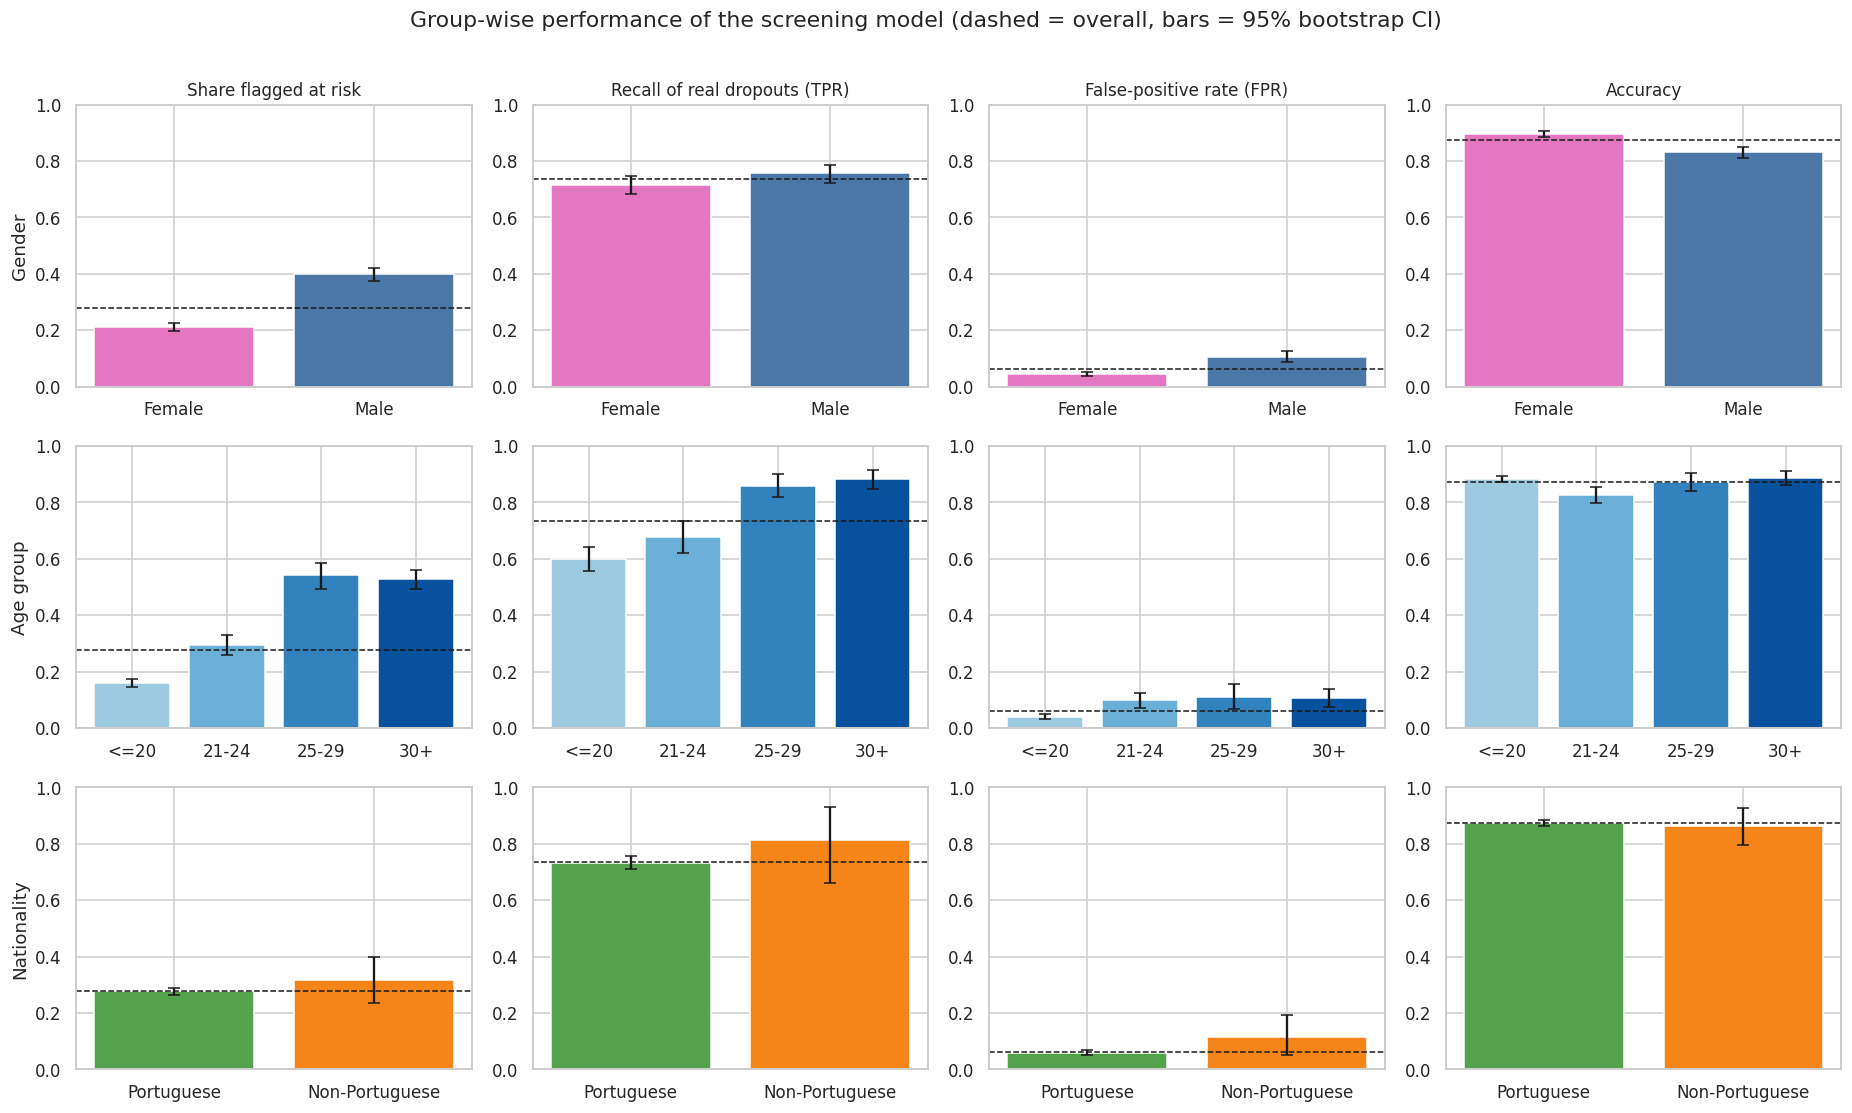

In [25]:
titles = {'flag_rate': 'Share flagged at risk', 'TPR': 'Recall of real dropouts (TPR)', 'FPR': 'False-positive rate (FPR)', 'accuracy': 'Accuracy'}
pal = {'Gender': ['#E377C2', '#4C78A8'], 'Age group': ['#9ecae1', '#6baed6', '#3182bd', '#08519c'], 'Nationality': ['#54A24B', '#F58518']}
fig, axes = plt.subplots(3, 4, figsize=(17, 10), sharey='col')
for r, attr in enumerate(order):
    sub = gt[gt.attribute == attr]
    for k, m in enumerate(METRICS):
        ax = axes[r, k]
        ax.bar(sub.group, sub[m], yerr=[sub[m] - sub[m + '_lo'], sub[m + '_hi'] - sub[m]], capsize=4, color=pal[attr])
        ax.axhline(mval(m, is_drop, fl_F), ls='--', c='k', lw=1)
        if r == 0: ax.set_title(titles[m], fontsize=11)
        if k == 0: ax.set_ylabel(attr, fontsize=12)
        ax.set_ylim(0, 1)
plt.suptitle('Group-wise performance of the screening model (dashed = overall, bars = 95% bootstrap CI)', y=1.01)
plt.tight_layout(); plt.savefig('figures/16_group_error_rates.png', bbox_inches='tight'); plt.show()

### 9.4 Are the gaps statistically real?
For each attribute and metric we take the **largest gap between groups** and run a **permutation test**: shuffle the group labels 2,000 times and see how often a gap this large appears by chance. This works for any number of groups and respects small group sizes. p-values are corrected across the 12 tests (Benjamini-Hochberg).

In [26]:
def gap_table(fl, B=2000):
    rows = []
    for attr, groups in order.items():
        lab = codes[attr]
        for metric in METRICS:
            vals = {g: mval(metric, is_drop[lab == i], fl[lab == i]) for i, g in enumerate(groups)}
            obs = max(vals.values()) - min(vals.values())
            rng = np.random.RandomState(1); null = np.empty(B)
            for b in range(B):
                pl = rng.permutation(lab)
                v = [mval(metric, is_drop[pl == i], fl[pl == i]) for i in range(len(groups))]
                null[b] = max(v) - min(v)
            rows.append(dict(attribute=attr, metric=metric, highest=max(vals, key=vals.get), lowest=min(vals, key=vals.get),
                             gap=obs, p_perm=(np.sum(null >= obs) + 1) / (B + 1)))
    out = pd.DataFrame(rows)
    out['p_FDR'] = multipletests(out.p_perm, method='fdr_bh')[1]
    out['significant'] = out.p_FDR < 0.05
    return out

gaps_F = gap_table(fl_F)
gaps_F.round(4).to_csv('fairness_gaps.csv', index=False)
gaps_F.round(4)

,attribute,metric,highest,lowest,gap,p_perm,p_FDR,significant
0,Gender,flag_rate,Male,Female,0.1871,0.0005,0.0010,True
1,Gender,TPR,Male,Female,0.0422,0.0830,0.1106,False
2,Gender,FPR,Male,Female,0.0627,0.0005,0.0010,True
3,Gender,accuracy,Female,Male,0.0638,0.0005,0.0010,True
4,Age group,flag_rate,25-29,<=20,0.3814,0.0005,0.0010,True
5,Age group,TPR,30+,<=20,0.2835,0.0005,0.0010,True
6,Age group,FPR,25-29,<=20,0.0697,0.0005,0.0010,True
7,Age group,accuracy,30+,21-24,0.0616,0.0025,0.0043,True
8,Nationality,flag_rate,Non-Portuguese,Portuguese,0.0414,0.3878,0.4231,False
9,Nationality,TPR,Non-Portuguese,Portuguese,0.0796,0.3068,0.3682,False


### 9.5 Does the model *rely* on features differently across groups? (SHAP by group)
We use the audit model (which also sees `Gender` and `International`). For every feature we compare the **absolute SHAP value for the Dropout class** between groups with a Kruskal-Wallis test and the effect size ε². A large ratio means the model leans on that feature much more for one group.

In [27]:
abs_sv = pd.DataFrame(np.abs(sv_S[:, :, c_drop]), columns=S_feats)
rows = []
for attr in order:
    lab = codes[attr]
    for f in S_feats:
        arrs = [abs_sv[f].values[lab == i] for i in range(len(order[attr]))]
        H, p = stats.kruskal(*arrs); n = sum(map(len, arrs)); k = len(arrs)
        means = [a.mean() for a in arrs]
        rows.append(dict(attribute=attr, feature=f, highest_group=order[attr][int(np.argmax(means))],
                         ratio_max_min=max(means) / max(min(means), 1e-9), eps2=max((H - k + 1) / (n - k), 0), p=p))
shap_diff = pd.DataFrame(rows)
shap_diff['p_FDR'] = multipletests(shap_diff.p, method='fdr_bh')[1]
shap_diff = shap_diff.sort_values('eps2', ascending=False).reset_index(drop=True)
shap_diff.round(4).to_csv('shap_group_differences.csv', index=False)
shap_diff.head(15).round(4)

,attribute,feature,highest_group,ratio_max_min,eps2,p,p_FDR
0,Age group,Age at enrollment,25-29,2.7841,0.4264,0.0,0.0
1,Gender,Gender,Male,1.5284,0.1600,0.0,0.0
2,Age group,Curricular units 1st sem (approved),25-29,1.3503,0.0950,0.0,0.0
3,Nationality,International,Non-Portuguese,33.1908,0.0674,0.0,0.0
4,Gender,Age at enrollment,Male,1.3007,0.0422,0.0,0.0
5,Age group,Tuition fees up to date,25-29,1.8252,0.0387,0.0,0.0
6,Age group,Curricular units 1st sem (evaluations),30+,1.6741,0.0333,0.0,0.0
7,Age group,Curricular units 2nd sem (approved),30+,1.2090,0.0326,0.0,0.0
8,Age group,Curricular units 1st sem (enrolled),30+,1.2718,0.0253,0.0,0.0
9,Gender,Curricular units 1st sem (approved),Male,1.1398,0.0244,0.0,0.0


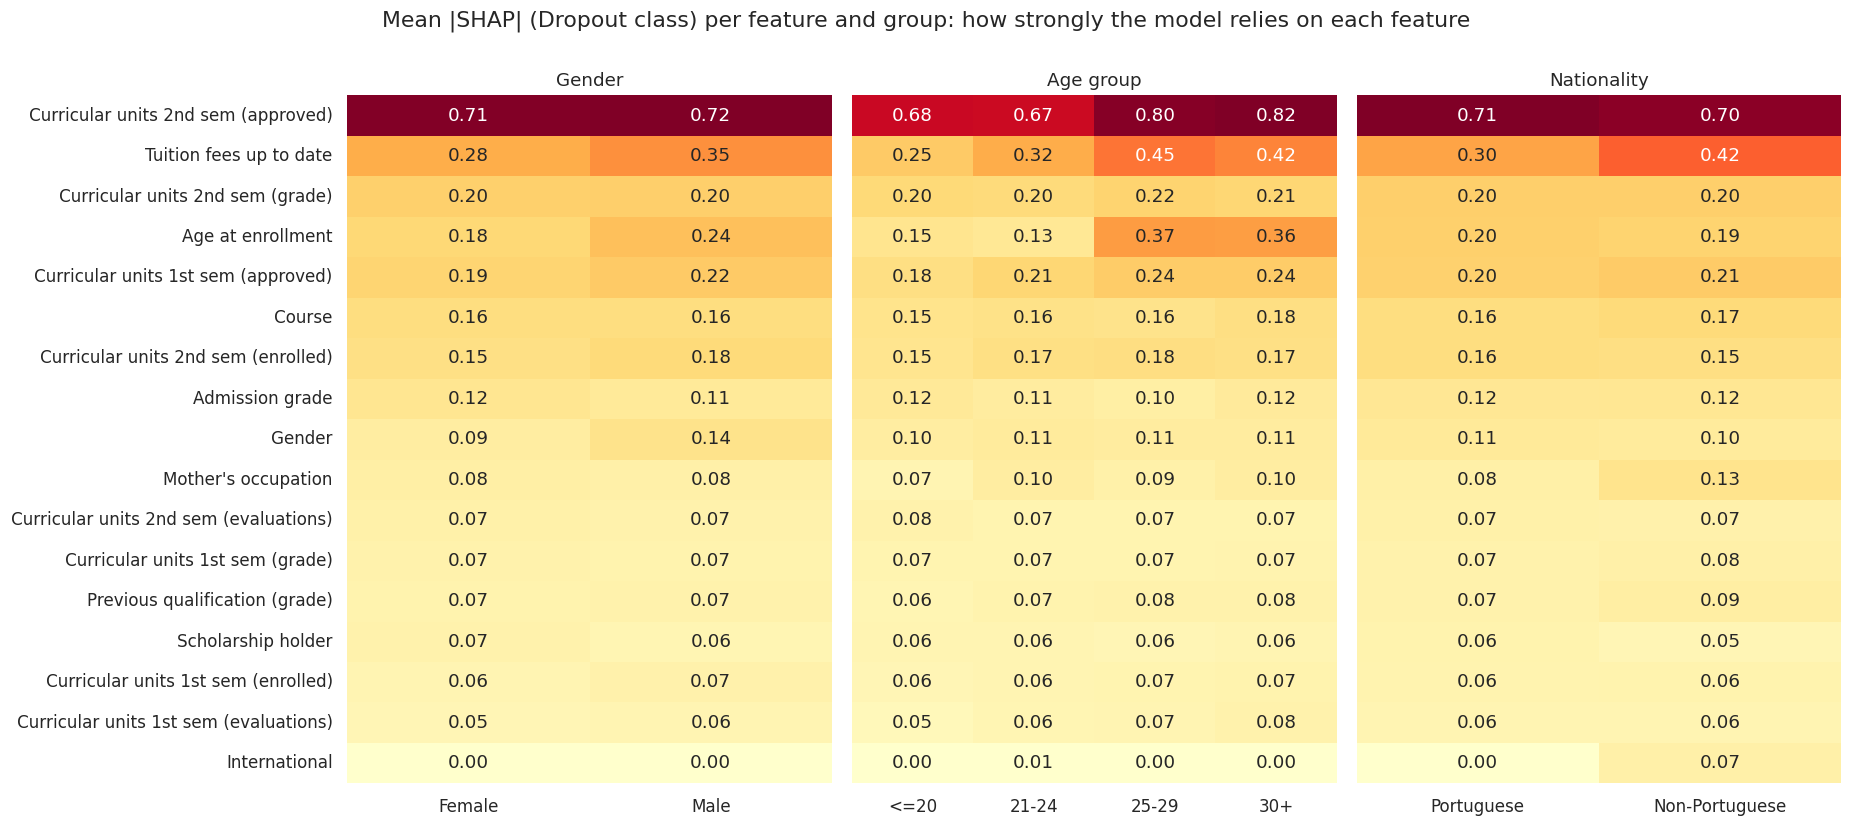

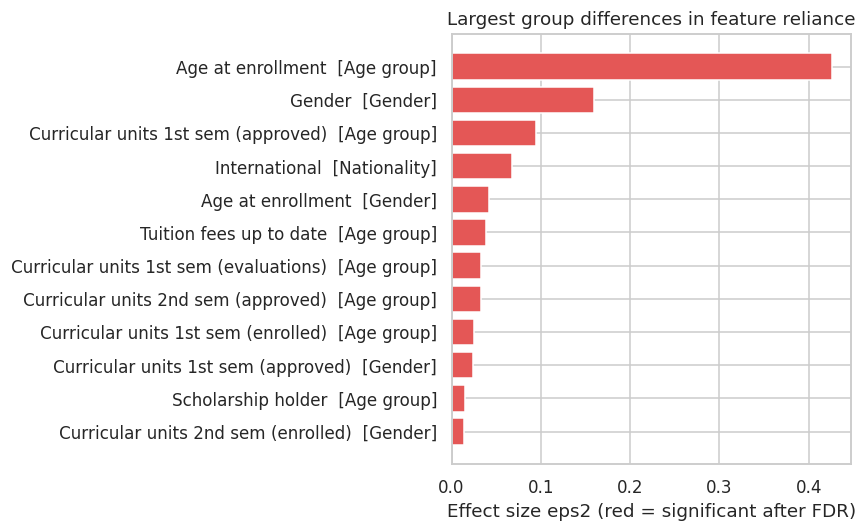

In [28]:
feat_order = abs_sv.mean().sort_values(ascending=False).index
fig, axes = plt.subplots(1, 3, figsize=(17, 7.5), sharey=True)
for ax, attr in zip(axes, order):
    M = pd.DataFrame({g: abs_sv.loc[codes[attr] == i, feat_order].mean() for i, g in enumerate(order[attr])})
    sns.heatmap(M, annot=True, fmt='.2f', cmap='YlOrRd', cbar=False, ax=ax)
    ax.set_title(attr)
plt.suptitle('Mean |SHAP| (Dropout class) per feature and group: how strongly the model relies on each feature', y=1.0)
plt.tight_layout(); plt.savefig('figures/17_shap_by_group_heatmap.png', bbox_inches='tight'); plt.show()

top = shap_diff.head(12).iloc[::-1]
plt.figure(figsize=(8, 5))
plt.barh(top.feature + '  [' + top.attribute + ']', top.eps2, color=np.where(top.p_FDR < 0.05, '#E45756', '#BBBBBB'))
plt.xlabel('Effect size eps2 (red = significant after FDR)'); plt.title('Largest group differences in feature reliance')
plt.tight_layout(); plt.savefig('figures/18_shap_group_effects.png', bbox_inches='tight'); plt.show()

### 9.6 Age reliance: matched comparison
A group can show a larger average |SHAP| for age simply because its students have different ages. To separate *different inputs* from *different treatment*, we compare **men and women within the same age band**: for the same age, does the model add the same amount of risk? We test each band with Mann-Whitney U and report Cliff's delta (effect size; |delta| < 0.15 negligible, 0.15-0.33 small, 0.33-0.47 medium, > 0.47 large).

age_band  n_female  n_male  mean_SHAP_female  mean_SHAP_male  cliffs_delta_F_vs_M      p  p_FDR
    <=18       792     249           -0.1098         -0.1386               0.1777 0.0000 0.0001
   19-20      1053     457           -0.1586         -0.1893               0.3158 0.0000 0.0000
   21-22       291     205           -0.1369         -0.1492               0.1642 0.0018 0.0022
   23-25       169     163            0.1221          0.1303              -0.0245 0.6999 0.6999
   26-30       207     176            0.3947          0.4347              -0.1934 0.0011 0.0017
     31+       356     306            0.3391          0.3781              -0.1744 0.0001 0.0002


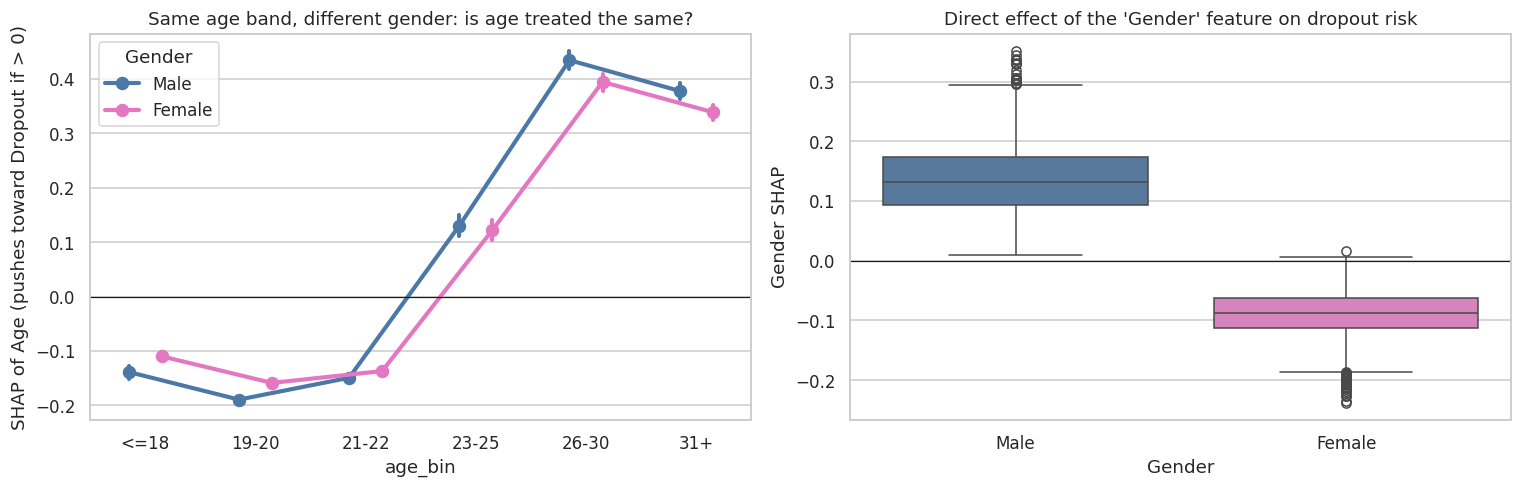

Share of total |SHAP| carried by Gender: 4.0%, International: 0.2%, Age: 7.6%


In [29]:
age_shap = sv_S[:, S_feats.index('Age at enrollment'), c_drop]
bin_order = ['<=18', '19-20', '21-22', '23-25', '26-30', '31+']
d = pd.DataFrame({'age_shap': age_shap, 'Gender': sens['Gender'].values,
                  'age_bin': pd.cut(X['Age at enrollment'], [0, 18, 20, 22, 25, 30, 100], labels=bin_order).astype(str)})
rows = []
for b in bin_order:
    s = d[d.age_bin == b]; f = s.loc[s.Gender == 'Female', 'age_shap']; m_ = s.loc[s.Gender == 'Male', 'age_shap']
    if min(len(f), len(m_)) >= 15:
        U, p = stats.mannwhitneyu(f, m_)
        rows.append(dict(age_band=b, n_female=len(f), n_male=len(m_), mean_SHAP_female=f.mean(), mean_SHAP_male=m_.mean(),
                         cliffs_delta_F_vs_M=2 * U / (len(f) * len(m_)) - 1, p=p))
    else:
        rows.append(dict(age_band=b, n_female=len(f), n_male=len(m_), p=np.nan))
match = pd.DataFrame(rows)
ok = match.p.notna(); match.loc[ok, 'p_FDR'] = multipletests(match.loc[ok, 'p'], method='fdr_bh')[1]
print(match.round(4).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
sns.pointplot(data=d, x='age_bin', y='age_shap', hue='Gender', order=bin_order, dodge=.3, errorbar=('ci', 95),
              palette={'Female': '#E377C2', 'Male': '#4C78A8'}, ax=axes[0])
axes[0].axhline(0, c='k', lw=.8); axes[0].set_ylabel('SHAP of Age (pushes toward Dropout if > 0)')
axes[0].set_title('Same age band, different gender: is age treated the same?')
sg = pd.DataFrame({'Gender SHAP': sv_S[:, S_feats.index('Gender'), c_drop], 'Gender': sens['Gender'].values})
sns.boxplot(data=sg, x='Gender', y='Gender SHAP', palette={'Female': '#E377C2', 'Male': '#4C78A8'}, ax=axes[1])
axes[1].axhline(0, c='k', lw=.8); axes[1].set_title("Direct effect of the 'Gender' feature on dropout risk")
plt.tight_layout(); plt.savefig('figures/19_age_reliance_matched.png', bbox_inches='tight'); plt.show()
share = np.abs(sv_S[:, :, c_drop]).mean(0); share = pd.Series(share / share.sum(), index=S_feats)
print(f"Share of total |SHAP| carried by Gender: {share['Gender']:.1%}, International: {share['International']:.1%}, Age: {share['Age at enrollment']:.1%}")

### 9.7 Proxy check: which other features are tied to the sensitive attributes?
Removing a sensitive feature does not remove its information if other features encode it (for example, a course that is mostly men or mostly women). We measure the association of each feature with each sensitive attribute (Cramér's V for categorical, ε² for numeric).

In [30]:
def assoc(attr, col):
    g = sens[attr].values
    if col in cat_cols:
        ct = pd.crosstab(X[col], g); chi2 = stats.chi2_contingency(ct)[0]
        return np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
    groups = [X.loc[g == u, col] for u in np.unique(g)]
    H = stats.kruskal(*groups)[0]; n = len(X); k = len(groups)
    return max((H - k + 1) / (n - k), 0)

excl = {'Gender': ['Gender'], 'Nationality': ['Nationality', 'International'], 'Age group': ['Age at enrollment']}
tabs = []
for attr in order:
    s = pd.Series({c: assoc(attr, c) for c in X.columns if c not in excl[attr]}).sort_values(ascending=False).head(6)
    tabs.append(pd.DataFrame({'attribute': attr, 'feature': s.index, 'association': s.values.round(3), 'used by model': [f in F_feats for f in s.index]}))
pd.concat(tabs, ignore_index=True)

,attribute,feature,association,used by model
0,Gender,Course,0.428,True
1,Gender,Application mode,0.188,False
2,Gender,Scholarship holder,0.169,True
3,Gender,Previous qualification,0.138,False
4,Gender,Father's occupation,0.134,False
5,Gender,Father's qualification,0.128,False
6,Age group,Application mode,0.505,False
7,Age group,Daytime/evening attendance,0.485,False
8,Age group,Displaced,0.392,False
9,Age group,Marital status,0.379,False


### 9.8 Mitigation experiments: does fixing it cost accuracy?
1. **Fairness through unawareness:** remove `Age at enrollment` (blind model B). Do the gaps shrink?
2. **Post-processing:** use a **separate decision threshold per group** so that every group has the same recall of real dropouts (equal opportunity). Thresholds are tuned on one random half of the students and evaluated on the other half, so the result is not over-optimistic.

In [31]:
def f1_bin(yt, fl):
    tp = ((fl == 1) & (yt == 1)).sum(); fp = ((fl == 1) & (yt == 0)).sum(); fn = ((fl == 0) & (yt == 1)).sum()
    return 2 * tp / max(2 * tp + fp + fn, 1)

def max_gap(fl, attr, metric, mask=None):
    mask = np.ones(len(fl), bool) if mask is None else mask
    v = [mval(metric, is_drop[mask & (codes[attr] == i)], fl[mask & (codes[attr] == i)]) for i in range(len(order[attr]))]
    return np.nanmax(v) - np.nanmin(v)

rows = []
for name, P in [('F: final model (with Age)', proba_F), ('S: + Gender, International', proba_S), ('B: blind (no Age)', proba_B)]:
    fl = flag(P)
    row = {'model': name, 'F1 (dropout flag)': f1_bin(is_drop, fl), 'accuracy': (fl == is_drop).mean()}
    for attr in order: row[f'TPR gap | {attr}'] = max_gap(fl, attr, 'TPR'); row[f'FPR gap | {attr}'] = max_gap(fl, attr, 'FPR')
    rows.append(row)
unaware = pd.DataFrame(rows).set_index('model').round(3)
unaware.T

model,F: final model (with Age),"S: + Gender, International",B: blind (no Age)
F1 (dropout flag),0.788,0.787,0.788
accuracy,0.873,0.873,0.873
TPR gap | Gender,0.042,0.065,0.024
FPR gap | Gender,0.063,0.081,0.050
TPR gap | Age group,0.283,0.283,0.222
FPR gap | Age group,0.070,0.079,0.041
TPR gap | Nationality,0.080,0.048,0.114
FPR gap | Nationality,0.055,0.041,0.043


Thresholds chosen on the tuning half: {'Gender': {'Female': np.float64(0.445), 'Male': np.float64(0.568)}, 'Age group': {'<=20': np.float64(0.261), '21-24': np.float64(0.486), '25-29': np.float64(0.727), '30+': np.float64(0.803)}, 'Nationality': {'Portuguese': np.float64(0.494), 'Non-Portuguese': np.float64(0.636)}}
  attribute                 rule  TPR_gap  FPR_gap    F1  accuracy  flag_rate
     Gender single threshold 0.5    0.055    0.086 0.791     0.878      0.275
     Gender     group thresholds    0.003    0.047 0.794     0.879      0.275
  Age group single threshold 0.5    0.286    0.086 0.791     0.878      0.275
  Age group     group thresholds    0.149    0.065 0.762     0.854      0.303
Nationality single threshold 0.5    0.057    0.039 0.791     0.878      0.275
Nationality     group thresholds    0.052    0.014 0.793     0.878      0.277


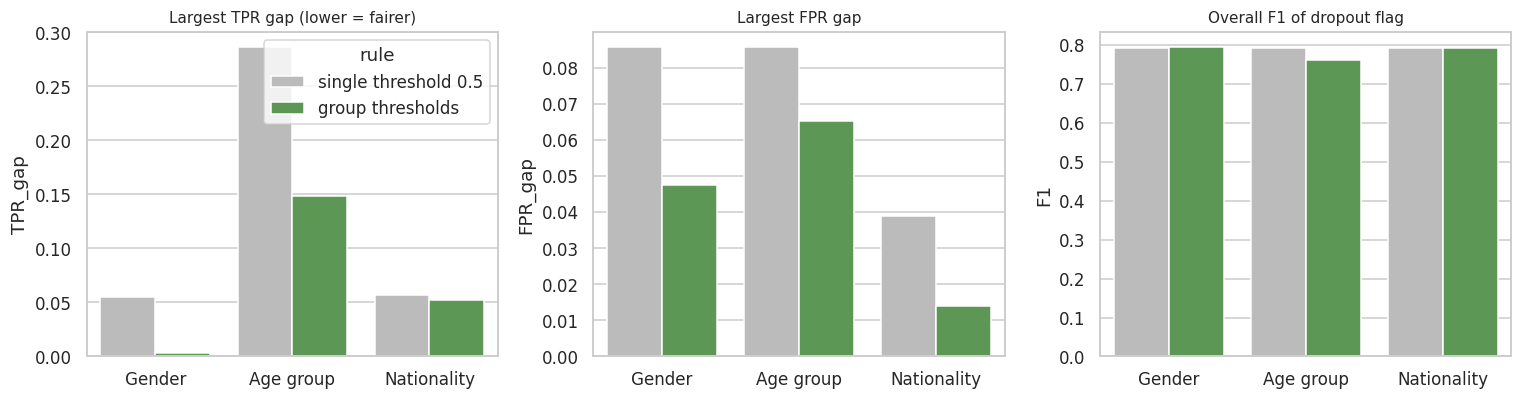

In [32]:
rng = np.random.RandomState(7)
tune = rng.rand(len(X)) < 0.5; ev = ~tune
pF = proba_F[:, c_drop]
target_tpr = (pF[tune & (is_drop == 1)] >= THR).mean()
rows, thr_report = [], {}
for attr in ['Gender', 'Age group', 'Nationality']:
    lab = codes[attr]
    thr = np.array([np.quantile(pF[tune & (lab == i) & (is_drop == 1)], 1 - target_tpr) for i in range(len(order[attr]))])
    thr_report[attr] = dict(zip(order[attr], thr.round(3)))
    for rule, fl in [('single threshold 0.5', (pF >= THR).astype(int)), ('group thresholds', (pF >= thr[lab]).astype(int))]:
        rows.append(dict(attribute=attr, rule=rule, TPR_gap=max_gap(fl, attr, 'TPR', ev), FPR_gap=max_gap(fl, attr, 'FPR', ev),
                         F1=f1_bin(is_drop[ev], fl[ev]), accuracy=(fl[ev] == is_drop[ev]).mean(), flag_rate=fl[ev].mean()))
post = pd.DataFrame(rows)
print('Thresholds chosen on the tuning half:', thr_report)
print(post.round(3).to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, col, ttl in zip(axes, ['TPR_gap', 'FPR_gap', 'F1'], ['Largest TPR gap (lower = fairer)', 'Largest FPR gap', 'Overall F1 of dropout flag']):
    sns.barplot(data=post, x='attribute', y=col, hue='rule', palette=['#BBBBBB', '#54A24B'], ax=ax); ax.set_title(ttl, fontsize=10); ax.set_xlabel('')
    if col != 'TPR_gap': ax.legend_.remove()
plt.tight_layout(); plt.savefig('figures/20_mitigation.png', bbox_inches='tight'); plt.show()

## 10. Staged early-warning: how do fairness gaps change over time?
A real early-warning system must act **before** a student has failed anything. So we rebuild the model three times, each time using **only what the university would know at that moment**:

| Stage | When | Information available |
|---|---|---|
| **S0** | at enrollment | personal data, family background, application and prior education, scholarship, economic context |
| **S1** | after semester 1 | S0 + semester-1 academic results + `Debtor` and `Tuition fees up to date` |
| **S2** | after semester 2 | S1 + semester-2 academic results |

*Assumption:* we treat `Debtor` and `Tuition fees up to date` as unknown at enrollment (they arise during the year), whereas `Scholarship holder` is known from the start. The dataset does not document timing, so state this as an assumption in your report.

**Fair comparison across stages.** Early models are less confident, so a fixed 0.5 threshold would flag very few students at S0. Instead, at every stage we flag the **top 30% highest-risk students** (a fixed support capacity, close to the 32% true dropout rate). Then the stages differ only in *how well the model ranks students*, not in how many are flagged.

**What we measure at each stage**
1. Overall quality: AUC, recall, precision.
2. Group-wise recall (TPR), false-positive rate and AUC for gender, age group and nationality.
3. Whether each gap is statistically real (permutation test) and whether it **changes** between stages (bootstrap).
4. How the SHAP explanations shift, especially the share of the model's reasoning that comes from sensitive attributes.
5. Whether removing sensitive attributes helps more at early stages.

In [33]:
# ---------- 10.1 define the three stages ----------
from sklearn.metrics import roc_auc_score, f1_score
sem1 = [c for c in X.columns if '1st sem' in c]
sem2 = [c for c in X.columns if '2nd sem' in c]
later_finance = ['Debtor', 'Tuition fees up to date']
stage_feats = {
    'Stage 0: enrollment': [c for c in X.columns if c not in sem1 + sem2 + later_finance],
    'Stage 1: after semester 1': [c for c in X.columns if c not in sem2],
    'Stage 2: after semester 2': list(X.columns),
}
stage_names = list(stage_feats)
short = dict(zip(stage_names, ['S0 enrollment', 'S1 after sem 1', 'S2 after sem 2']))
CAP = 0.30
pd.DataFrame({'number of features': {short[s]: len(f) for s, f in stage_feats.items()},
              'new information': {short[stage_names[0]]: 'personal, family, application, prior education, scholarship, economy',
                                   short[stage_names[1]]: '+ semester-1 results, debtor, tuition status',
                                   short[stage_names[2]]: '+ semester-2 results'}})

,number of features,new information
S0 enrollment,22,"personal, family, application, prior education..."
S1 after sem 1,30,"+ semester-1 results, debtor, tuition status"
S2 after sem 2,36,+ semester-2 results


In [34]:
# ---------- 10.2 out-of-fold predictions and SHAP values for each stage ----------
stage_proba, stage_sv = {}, {}
for s in stage_names:
    stage_proba[s], stage_sv[s] = oof_predict(stage_feats[s], with_shap=True)

def flag_top(P, share=CAP):
    p = P[:, c_drop]
    return (p >= np.quantile(p, 1 - share)).astype(int)

flags = {s: flag_top(stage_proba[s]) for s in stage_names}
perf = pd.DataFrame({short[s]: {
    '3-class accuracy': (stage_proba[s].argmax(1) == y.values).mean(),
    'macro-F1': f1_score(y, stage_proba[s].argmax(1), average='macro'),
    'Dropout AUC': roc_auc_score(is_drop, stage_proba[s][:, c_drop]),
    f'recall of dropouts (top {CAP:.0%} flagged)': mval('TPR', is_drop, flags[s]),
    f'precision (top {CAP:.0%} flagged)': is_drop[flags[s] == 1].mean(),
} for s in stage_names}).round(3)
perf

,S0 enrollment,S1 after sem 1,S2 after sem 2
3-class accuracy,0.620,0.750,0.781
macro-F1,0.509,0.668,0.712
Dropout AUC,0.772,0.906,0.926
recall of dropouts (top 30% flagged),0.560,0.742,0.766
precision (top 30% flagged),0.600,0.795,0.821


### 10.3 Group-wise recall, false alarms and AUC at each stage (with bootstrap 95% CIs)

In [35]:
def stage_group_table(s, B=300):
    fl, p = flags[s], stage_proba[s][:, c_drop]
    rows = []
    for attr in order:
        for i, g in enumerate(order[attr]):
            idx = np.where(codes[attr] == i)[0]
            r = dict(stage=s, attribute=attr, group=g, n=len(idx), TPR=mval('TPR', is_drop[idx], fl[idx]),
                     FPR=mval('FPR', is_drop[idx], fl[idx]), flag_rate=fl[idx].mean(), AUC=roc_auc_score(is_drop[idx], p[idx]))
            rng = np.random.RandomState(0); bs = []
            for _ in range(B):
                b = rng.choice(idx, len(idx))
                bs.append([mval('TPR', is_drop[b], fl[b]), mval('FPR', is_drop[b], fl[b]), roc_auc_score(is_drop[b], p[b])])
            bs = np.array(bs)
            for k, m in enumerate(['TPR', 'FPR', 'AUC']):
                r[m + '_lo'], r[m + '_hi'] = np.nanpercentile(bs[:, k], 2.5), np.nanpercentile(bs[:, k], 97.5)
            rows.append(r)
    return pd.DataFrame(rows)

stage_gt = pd.concat([stage_group_table(s) for s in stage_names], ignore_index=True)
stage_gt['stage_short'] = stage_gt.stage.map(short)
print('Recall of real dropouts (TPR) by group and stage:')
stage_gt.pivot_table(index=['attribute', 'group'], columns='stage_short', values='TPR', sort=False).round(3)

Recall of real dropouts (TPR) by group and stage:


stage_short                 S0 enrollment  S1 after sem 1  S2 after sem 2
attribute   group                                                        
Gender      Female                  0.428           0.699           0.738
            Male                    0.696           0.787           0.796
Age group   <=20                    0.240           0.594           0.642
            21-24                   0.504           0.710           0.746
            25-29                   0.882           0.886           0.866
            30+                     0.842           0.881           0.891
Nationality Portuguese              0.562           0.742           0.766
            Non-Portuguese          0.500           0.781           0.781

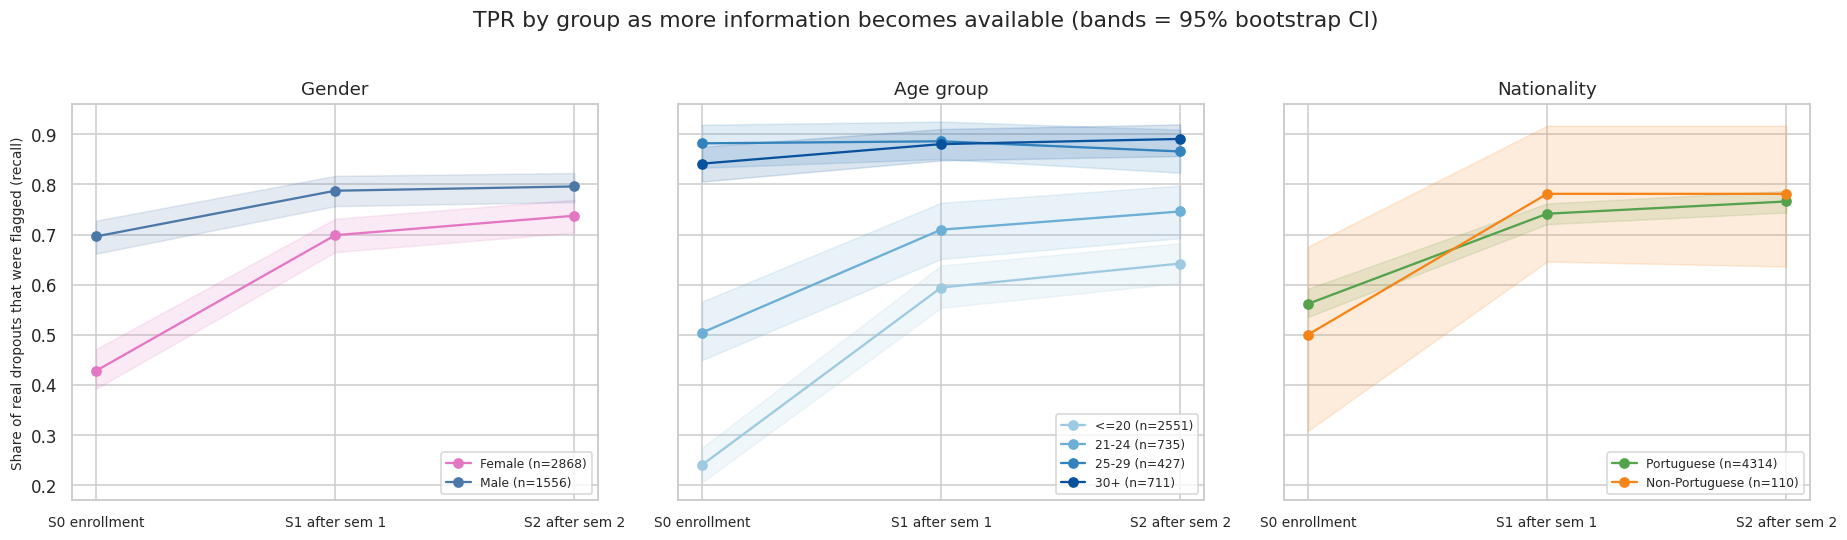

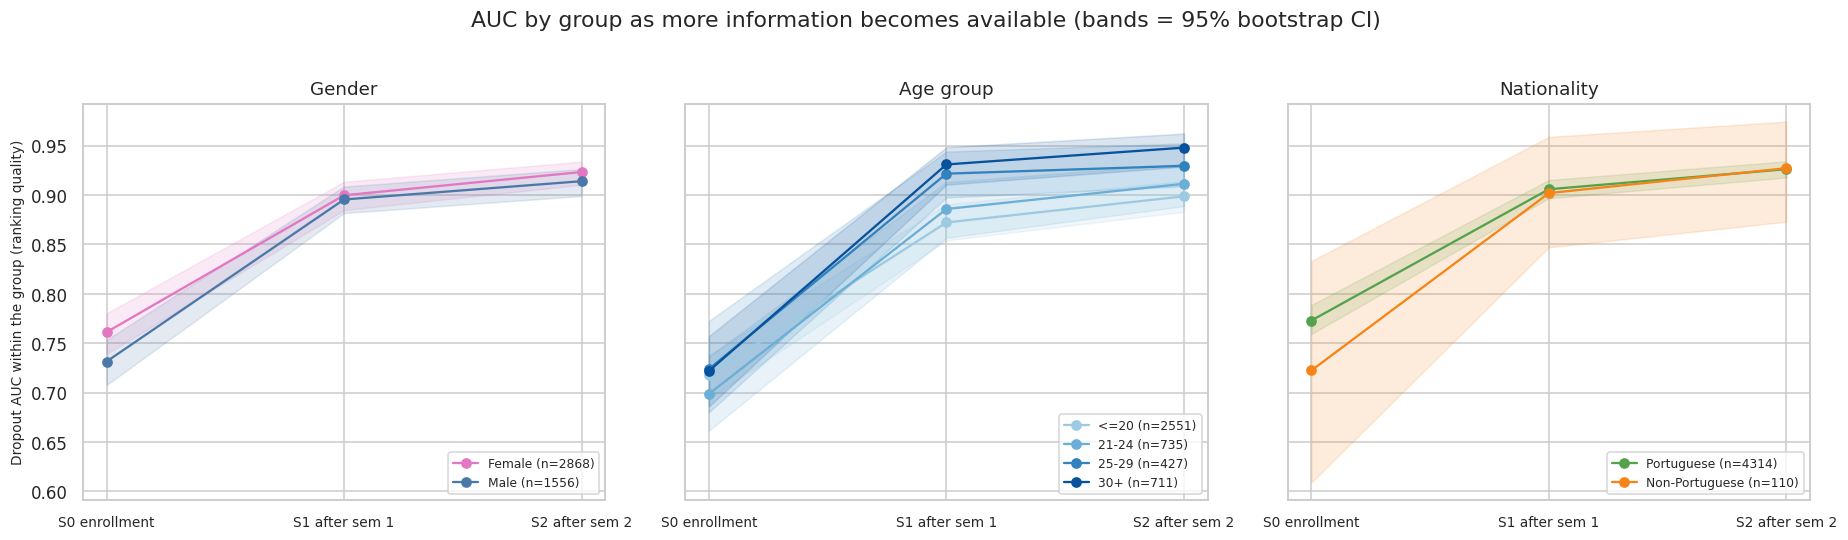

In [36]:
x = np.arange(len(stage_names))
for metric, ylabel, fname in [('TPR', 'Share of real dropouts that were flagged (recall)', '21_stage_tpr_by_group.png'),
                              ('AUC', 'Dropout AUC within the group (ranking quality)', '22_stage_auc_by_group.png')]:
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), sharey=True)
    for ax, attr in zip(axes, order):
        for g, col in zip(order[attr], pal[attr]):
            sub = stage_gt[(stage_gt.attribute == attr) & (stage_gt.group == g)].set_index('stage').loc[stage_names]
            ax.plot(x, sub[metric], marker='o', color=col, label=f'{g} (n={sub.n.iloc[0]})')
            ax.fill_between(x, sub[metric + '_lo'], sub[metric + '_hi'], color=col, alpha=.15)
        ax.set_xticks(x); ax.set_xticklabels([short[s] for s in stage_names], fontsize=9); ax.set_title(attr); ax.legend(fontsize=8, loc='lower right')
    axes[0].set_ylabel(ylabel, fontsize=9)
    plt.suptitle(f'{metric} by group as more information becomes available (bands = 95% bootstrap CI)', y=1.02)
    plt.tight_layout(); plt.savefig('figures/' + fname, bbox_inches='tight'); plt.show()

### 10.4 Do the fairness gaps shrink or grow as data arrives?
For each stage, attribute and metric (recall, false-positive rate) we compute the **largest gap between groups**, test it with a permutation test (2,000 shuffles, FDR-corrected across all stage x attribute x metric tests), and then use a **bootstrap** over students to see whether the gap at S2 differs from the gap at S0. A change whose 95% interval excludes 0 is a real change.

*Caution:* for very small groups (non-Portuguese, n = 110) the largest-minus-smallest gap is noisy and tends to be inflated, so read nationality results with care.

In [37]:
# permutation tests of the gap, per stage
perm_all = pd.concat([gap_table(flags[s]).assign(stage=s) for s in stage_names], ignore_index=True)
perm_all['p_FDR_all'] = multipletests(perm_all.p_perm, method='fdr_bh')[1]
perm_all['sig'] = perm_all.p_FDR_all < 0.05
perm_all['stage_short'] = perm_all.stage.map(short)
perm_all.round(4).to_csv('stage_fairness_gaps.csv', index=False)
view = perm_all[perm_all.metric.isin(['TPR', 'FPR'])].copy()
view['gap (sig *)'] = view.gap.round(3).astype(str) + np.where(view.sig, ' *', '')
view.pivot_table(index=['attribute', 'metric'], columns='stage_short', values='gap (sig *)', aggfunc='first', sort=False)

stage_short        S0 enrollment S1 after sem 1 S2 after sem 2
attribute   metric                                            
Gender      TPR          0.268 *        0.089 *        0.059 *
            FPR          0.256 *        0.086 *        0.094 *
Age group   TPR          0.642 *        0.292 *        0.249 *
            FPR          0.574 *        0.121 *        0.135 *
Nationality TPR            0.062           0.04          0.015
            FPR             0.01          0.052          0.037

In [38]:
def gap_value(fl, attr, metric, idx):
    lab = codes[attr][idx]; yt = is_drop[idx]; f = fl[idx]
    v = [mval(metric, yt[lab == i], f[lab == i]) for i in range(len(order[attr]))]
    return np.nanmax(v) - np.nanmin(v)

full = np.arange(len(X)); rng = np.random.RandomState(3)
boot_idx = [rng.randint(0, len(X), len(X)) for _ in range(1000)]
gap_res, rows = {}, []
for attr in order:
    for metric in ['TPR', 'FPR']:
        obs = np.array([gap_value(flags[s], attr, metric, full) for s in stage_names])
        G = np.array([[gap_value(flags[s], attr, metric, b) for s in stage_names] for b in boot_idx])
        lo, hi = np.percentile(G, 2.5, axis=0), np.percentile(G, 97.5, axis=0)
        chg = G[:, 2] - G[:, 0]
        gap_res[(attr, metric)] = (obs, lo, hi)
        rows.append(dict(attribute=attr, metric=metric, gap_S0=obs[0], gap_S1=obs[1], gap_S2=obs[2],
                         change_S0_to_S2=obs[2] - obs[0], change_CI_low=np.percentile(chg, 2.5), change_CI_high=np.percentile(chg, 97.5),
                         real_change=(np.percentile(chg, 2.5) > 0) or (np.percentile(chg, 97.5) < 0)))
change_tab = pd.DataFrame(rows)
change_tab.round(3).to_csv('stage_gap_changes.csv', index=False)
change_tab.round(3)

,attribute,metric,gap_S0,gap_S1,gap_S2,change_S0_to_S2,change_CI_low,change_CI_high,real_change
0,Gender,TPR,0.268,0.089,0.059,-0.210,-0.269,-0.157,True
1,Gender,FPR,0.256,0.086,0.094,-0.163,-0.199,-0.125,True
2,Age group,TPR,0.642,0.292,0.249,-0.393,-0.458,-0.325,True
3,Age group,FPR,0.574,0.121,0.135,-0.439,-0.525,-0.352,True
4,Nationality,TPR,0.062,0.040,0.015,-0.046,-0.197,0.118,False
5,Nationality,FPR,0.010,0.052,0.037,0.027,-0.071,0.084,False


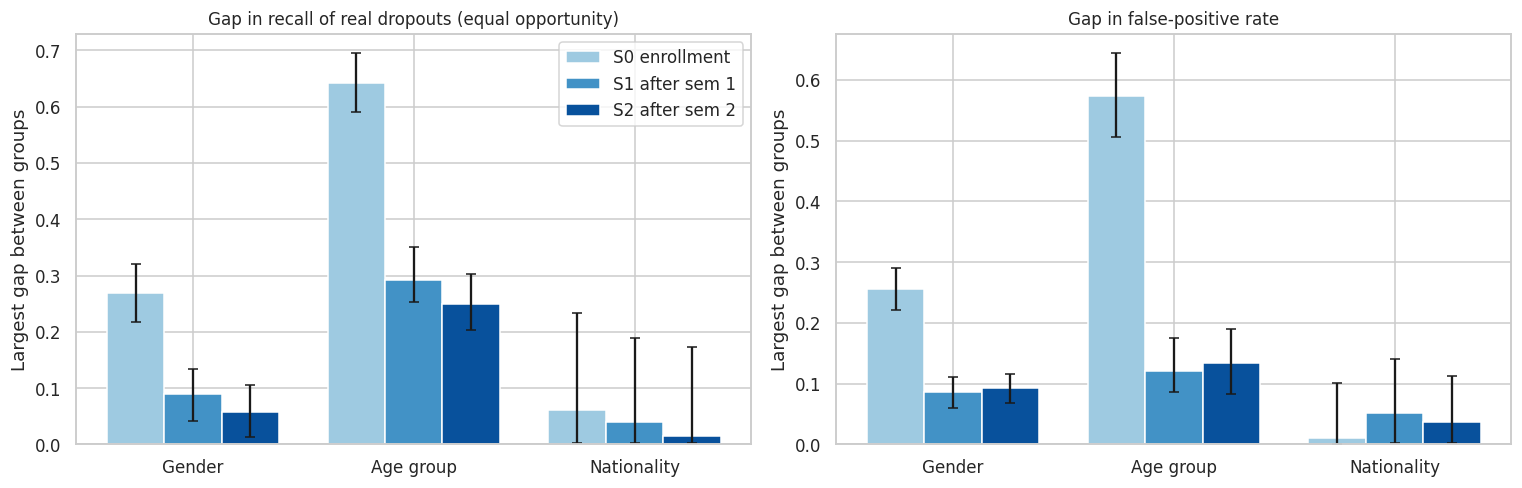

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
w = 0.26; cols = ['#9ecae1', '#4292c6', '#08519c']
for ax, metric in zip(axes, ['TPR', 'FPR']):
    for k, s in enumerate(stage_names):
        vals = [gap_res[(a, metric)][0][k] for a in order]
        lo = [gap_res[(a, metric)][1][k] for a in order]; hi = [gap_res[(a, metric)][2][k] for a in order]
        yerr = np.array([np.maximum(np.array(vals) - lo, 0), np.maximum(np.array(hi) - vals, 0)])
        ax.bar(np.arange(3) + (k - 1) * w, vals, w, yerr=yerr, capsize=3, color=cols[k], label=short[s])
    ax.set_xticks(np.arange(3)); ax.set_xticklabels(list(order)); ax.set_ylabel('Largest gap between groups')
    ax.set_title({'TPR': 'Gap in recall of real dropouts (equal opportunity)', 'FPR': 'Gap in false-positive rate'}[metric], fontsize=11)
axes[0].legend()
plt.tight_layout(); plt.savefig('figures/23_stage_gaps.png', bbox_inches='tight'); plt.show()

### 10.5 How do the *reasons* change across stages? (SHAP)
We group features into families and measure the **share of the model's total |SHAP|** that each family carries at each stage. We also track how much of the reasoning comes from sensitive attributes (age, gender, nationality, international status).

Top-5 features by share of |SHAP| at each stage:
           S0 enrollment                            S1 after sem 1                            S2 after sem 2
 Age at enrollment (20%) Curricular units 1st sem (approved) (22%) Curricular units 2nd sem (approved) (22%)
Scholarship holder (12%)             Tuition fees up to date (12%)             Tuition fees up to date (10%)
            Gender (10%)     Curricular units 1st sem (grade) (8%)  Curricular units 1st sem (approved) (7%)
             Course (9%)                    Age at enrollment (6%)     Curricular units 2nd sem (grade) (6%)
   Application mode (8%)  Curricular units 1st sem (enrolled) (6%)                    Age at enrollment (6%)

Share of total |SHAP| carried by sensitive attributes:
               Age at enrollment Gender Nationality International  \
stage                                                               
S0 enrollment              19.9%   9.6%        0.2%          0.1%   
S1 after sem 1              6.3%  

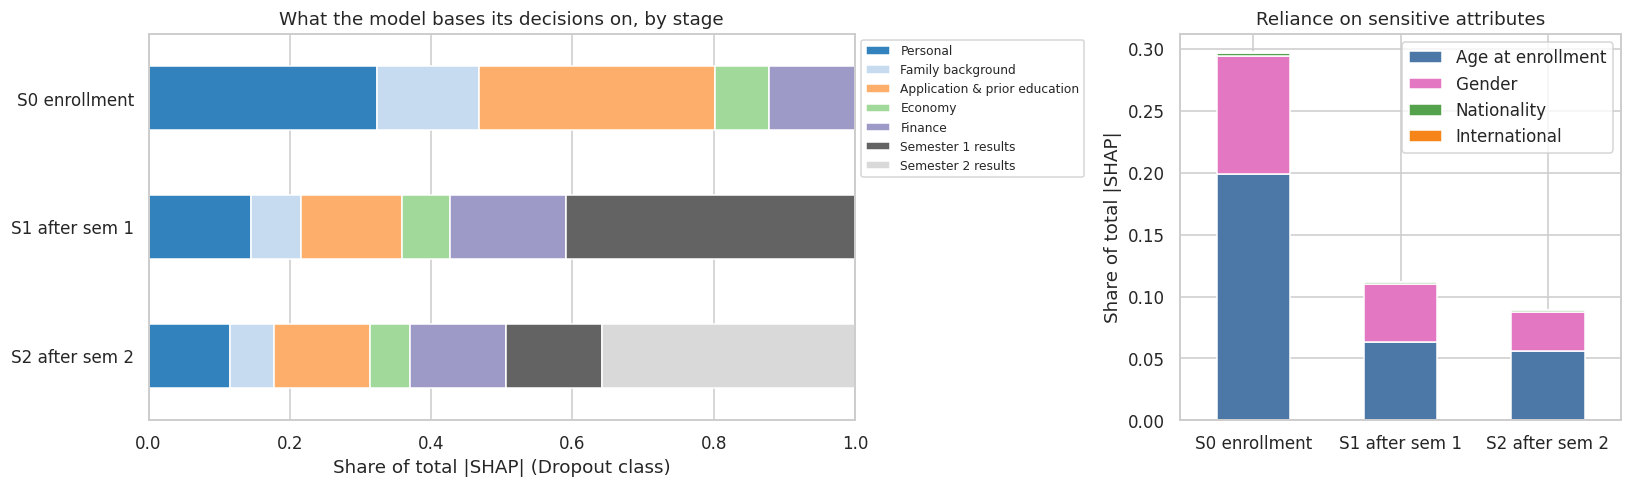

In [40]:
def category(f):
    if '1st sem' in f: return 'Semester 1 results'
    if '2nd sem' in f: return 'Semester 2 results'
    if f in ['Debtor', 'Tuition fees up to date', 'Scholarship holder']: return 'Finance'
    if f in ['Age at enrollment', 'Gender', 'Nationality', 'International', 'Marital status', 'Displaced', 'Educational special needs']: return 'Personal'
    if "Mother's" in f or "Father's" in f: return 'Family background'
    if f in ['Unemployment rate', 'Inflation rate', 'GDP']: return 'Economy'
    return 'Application & prior education'

sens_feats = ['Age at enrollment', 'Gender', 'Nationality', 'International']
cat_order = ['Personal', 'Family background', 'Application & prior education', 'Economy', 'Finance', 'Semester 1 results', 'Semester 2 results']
share_rows, sens_rows, top_rows = [], [], {}
for s in stage_names:
    m = pd.Series(np.abs(stage_sv[s][:, :, c_drop]).mean(0), index=stage_feats[s]); m = m / m.sum()
    cat_share = m.groupby(lambda f: category(f)).sum().reindex(cat_order).fillna(0)
    share_rows.append(cat_share.rename(short[s]))
    sens_rows.append(dict(stage=short[s], **{f: m.get(f, 0) for f in sens_feats}, all_sensitive=m.reindex(sens_feats).fillna(0).sum()))
    top_rows[short[s]] = [f'{f} ({v:.0%})' for f, v in m.sort_values(ascending=False).head(5).items()]
share_cat = pd.DataFrame(share_rows)
sens_share = pd.DataFrame(sens_rows).set_index('stage')
print('Top-5 features by share of |SHAP| at each stage:')
print(pd.DataFrame(top_rows).to_string(index=False))
print()
print('Share of total |SHAP| carried by sensitive attributes:')
print((sens_share * 100).round(1).astype(str) + '%')

fig, axes = plt.subplots(1, 2, figsize=(15, 4.6), gridspec_kw={'width_ratios': [1.6, 1]})
share_cat.plot(kind='barh', stacked=True, ax=axes[0], colormap='tab20c'); axes[0].invert_yaxis()
axes[0].set_xlabel('Share of total |SHAP| (Dropout class)'); axes[0].set_title('What the model bases its decisions on, by stage')
axes[0].legend(bbox_to_anchor=(1.0, 1.0), fontsize=8)
sens_share[sens_feats].plot(kind='bar', stacked=True, ax=axes[1], color=['#4C78A8', '#E377C2', '#54A24B', '#F58518'], rot=0)
axes[1].set_ylabel('Share of total |SHAP|'); axes[1].set_title('Reliance on sensitive attributes'); axes[1].set_xlabel('')
plt.tight_layout(); plt.savefig('figures/24_stage_shap_shares.png', bbox_inches='tight'); plt.show()

### 10.6 Does removing sensitive attributes help more at early stages?
At S0 the model has little else to go on, so it may lean on age, gender and nationality heavily. We retrain each stage **without** `Age at enrollment`, `Gender`, `Nationality` and `International` and compare the recall gaps and the ranking quality (AUC).

         stage                      variant   AUC  recall  TPR gap | Gender  TPR gap | Age group  TPR gap | Nationality
 S0 enrollment    with sensitive attributes 0.772   0.560             0.268                0.642                  0.062
 S0 enrollment without sensitive attributes 0.763   0.552             0.112                0.504                  0.042
S1 after sem 1    with sensitive attributes 0.906   0.742             0.089                0.292                  0.040
S1 after sem 1 without sensitive attributes 0.906   0.740             0.040                0.252                  0.106
S2 after sem 2    with sensitive attributes 0.926   0.766             0.059                0.249                  0.015
S2 after sem 2 without sensitive attributes 0.925   0.764             0.027                0.227                  0.050


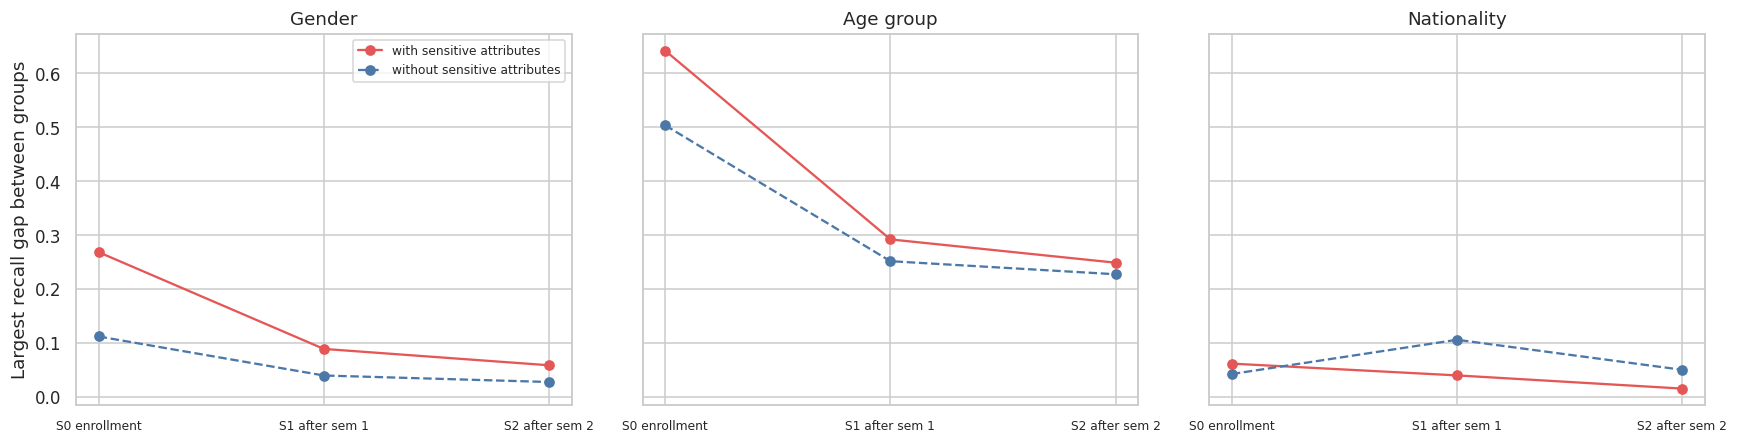

In [41]:
blind_proba = {s: oof_predict([f for f in stage_feats[s] if f not in sens_feats])[0] for s in stage_names}
blind_flags = {s: flag_top(blind_proba[s]) for s in stage_names}
rows = []
for s in stage_names:
    for variant, P, fl in [('with sensitive attributes', stage_proba[s], flags[s]), ('without sensitive attributes', blind_proba[s], blind_flags[s])]:
        r = dict(stage=short[s], variant=variant, AUC=roc_auc_score(is_drop, P[:, c_drop]), recall=mval('TPR', is_drop, fl))
        for attr in order: r[f'TPR gap | {attr}'] = max_gap(fl, attr, 'TPR')
        rows.append(r)
blind_tab = pd.DataFrame(rows); blind_tab.round(3).to_csv('stage_blind_comparison.csv', index=False)
print(blind_tab.round(3).to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), sharey=True)
for ax, attr in zip(axes, order):
    for variant, ls, col in [('with sensitive attributes', '-', '#E45756'), ('without sensitive attributes', '--', '#4C78A8')]:
        sub = blind_tab[blind_tab.variant == variant]
        ax.plot(sub.stage, sub[f'TPR gap | {attr}'], marker='o', ls=ls, color=col, label=variant)
    ax.set_title(attr); ax.tick_params(axis='x', labelsize=8)
axes[0].set_ylabel('Largest recall gap between groups'); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig('figures/25_stage_blind_gaps.png', bbox_inches='tight'); plt.show()

## 11. Conclusions (fill in with your own numbers)
**Classic analysis**
* **Statistics:** features with the largest effect sizes (section 2) and Dunn's post-hoc results.
* **Feature selection & Friedman:** which model ranks best and whether the 15-feature model is equivalent to the full model (sections 4 and 4b).
* **Explainability:** SHAP gives global drivers and directions, LIME gives local explanations, and section 8 measures how much they agree.

**Fairness through explanations (section 9)**
* Which groups have significantly different recall (missed dropouts) or false-positive rates (tables 9.3-9.4)?
* Does the model rely on some features more for one group (9.5), and does it treat the same age differently for men and women (9.6)?
* Does removing age help, or do proxies keep the gaps (9.7-9.8)? What does group-specific thresholding cost?

**Staged early warning (section 10)**
* How good is the model at enrollment compared with after semester 1 and 2 (10.2)?
* At which stage are young or older students, men or women, caught or missed, and do the gaps shrink as academic data arrives (10.3-10.4)?
* How do the reasons change: personal and background features dominate early, academic results later (10.5), and does removing sensitive attributes matter more early on (10.6)?

**Limitations:** one institution; the timing of finance variables is assumed; small groups such as non-Portuguese students give wide confidence intervals; "Enrolled" outcomes are not final; SHAP describes model behaviour, not causes; using gender, age or nationality to make decisions about real students raises legal and ethical issues beyond this analysis; differences in error rates may reflect real differences in the data and not only model bias.